# Exercice 1: Learning a WGAN for synthetic 2-dimensional datasets

<br/><br/><br/><br/>

This practical session contains
- "QUESTION" fields in the text, that you should answer
- blocks of code that you should complete at every region marked with ### ... ###

We advise you to open the notebook on Google Colab.

### Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

if torch.cuda.is_available():
    device = torch.device('cuda')
    dtype = torch.cuda.FloatTensor
else:
    device = torch.device('cpu')
    dtype = torch.FloatTensor

# If you don't want to bother with the device, stay on cpu:
# device = torch.device('cpu')

print(device)

cpu


### Target Measure

In the following cell, we define the discrete target measure $\nu$ that will serve as dataset for this practical session.

The variable `xgrid` contains a grid of points that will be useful below to display the discriminators along training.

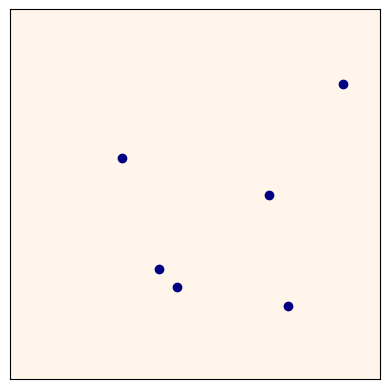

In [ ]:
d = 2   # dimension of the data points

# First dataset with 6 points
n = 6
y = torch.zeros((n,d), device=device)
y[0, 0] = 0.9
y[0, 1] = 0.2
y[1, 0] = 0.75
y[1, 1] = 0.8
y[2, 0] = 0.3
y[2, 1] = 0.4
y[3, 0] = 0.4
y[3, 1] = 0.7
y[4, 0] = 0.45
y[4, 1] = 0.75
y[5, 0] = 0.7
y[5, 1] = 0.5

# # Second dataset with 100 points
# n = 100
# t = torch.pi*torch.linspace(-.2,1.2,n)
# y = .05*torch.randn((n,d))
# y[:,0] += torch.cos(t)
# y[:,1] += torch.sin(2*t)
# y = .5 + .3*y
# y = y.to(device)

# Define masses (empirical measure on the data points)
nu = torch.ones(n, device=device)/n

# generate grid for plotting purpose
nr,nc = 256,256
extent = ((-0.5/nc, 1-0.5/nc, 1-0.5/nr, -0.5/nr))
xs = torch.linspace(0, 1, steps=nr)
ys = torch.linspace(0, 1, steps=nc)
xm, ym = torch.meshgrid(xs, ys, indexing='ij')
xm = xm.T
ym = ym.T
xgrid = torch.cat((xm.reshape(nr*nc,1),ym.reshape(nr*nc,1)),1).to(device)

# Plot data points
fig = plt.figure(dpi=100)
plt.xticks([])
plt.yticks([])
plt.imshow(np.zeros((nr,nc)),cmap = 'Oranges', extent=extent) # background
plt.scatter(y[:, 0].cpu(), y[:,1].cpu(),c='navy')
plt.show()

## Define Generator architecture

QUESTION: Examine the layers and parameters of the following generative network.

Write a short description of the architecture of this network.

n_in: The dimensionality of the input vector.
n_out: The dimensionality of the output vector.
nlayers: The generator consists of nlayers hidden layers, each containing a linear transformation followed by the ELU (Exponential Linear Unit) activation function.
Each hidden layer transforms its input (n_in_t) to an output of size n_hid.
The number of hidden units in each layer is specified by n_hid.
The output layer is a single linear transformation followed by the Sigmoid activation function.
It transforms the hidden layer representation (n_hid) to the output vector of size n_out.
The weights of the linear layers are initialized using Xavier uniform initialization with a gain factor of 1.0, which helps in reducing the variance of the gradients during training.
The biases are initialized to zeros.

In [ ]:
class Generator(torch.nn.Module):

    def __init__(self, n_in, n_out, n_hid=10, nlayers=3, device=torch.device("cpu")):
        super(Generator, self).__init__()

        self.n_in = n_in
        self.n_out = n_out
        self.n_hid = n_hid
        self.nlayers = nlayers
        self.hidden = nn.ModuleList()

        for n in range(nlayers):
            n_in_t = n_in if n==0 else n_hid
            self.hidden.append(nn.Sequential(
            nn.Linear(n_in_t, n_hid),
            nn.ELU(1)
        ).to(device))

        self.out = nn.Sequential(
            nn.Linear(n_hid, n_out),
            nn.Sigmoid()
        ).to(device)

        self.apply(self._init_weights)


    def forward(self, x):
        for n in range(self.nlayers):
            x = self.hidden[n](x)
        x = self.out(x)
        return x


    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.xavier_uniform_(module.weight, 1.0)
            if module.bias is not None:
                module.bias.data.zero_()


QUESTION: Plot one initial configuration of the generator (draw a batch of generated points)

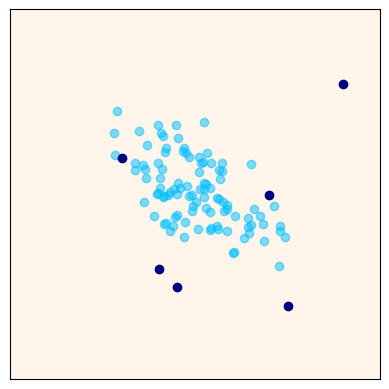

In [ ]:
torch.manual_seed(0)  # initialize random seed for reproducibility

n_in = 10    # dimension of the input noise
b = 100      # batch size

# Initialize generator
G = Generator(n_in=n_in, n_out=d, n_hid=100, nlayers=3, device=device)

# Draw a batch x of generated points
#    Input noise z : standard normal with shape (b, n_in)

### ... ###
z = torch.randn(b, n_in, device=device)

# Generate points using the generator
with torch.no_grad():
    x = G(z)
# Plot
xd = x.detach()
fig = plt.figure(dpi=100)
plt.xticks([])
plt.yticks([])
plt.imshow(np.zeros((nr,nc)),cmap = 'Oranges', extent=extent) # background
plt.scatter(xd[:, 0].cpu(), xd[:,1].cpu(),c='deepskyblue',alpha=.5)
plt.scatter(y[:, 0].cpu(), y[:,1].cpu(),c='navy')
plt.show()

## Define Discriminator Architecture

In [ ]:
class Discriminator(nn.Module):
  def __init__(self, n_in, n_hid=10):
    super(Discriminator, self).__init__()

    self.n_hid = n_hid
    self.n_in = n_in

    self.fc1 = nn.Linear(n_in, n_hid)
    self.fc2 = nn.Linear(n_hid, n_hid)
    self.fc3 = nn.Linear(n_hid, 1)

  def forward(self, x):
    y = nn.LeakyReLU(negative_slope=0.2)(self.fc1(x))
    y = nn.LeakyReLU(negative_slope=0.2)(self.fc2(y))
    y = self.fc3(y)
    return y

## Discriminator training with Weight clipping

QUESTION: For a fixed generator, train the discriminator with WGAN loss and weight clipping.

Try changing the clip_value. What do you observe?

We can see that the clip value has 2 effects, it gives a better score, but it also increases the lipschitz constant of the discriminator. Thus, we need to tweak this clip value in order to have a lipschitz constant around 1.

[0/1000], -0.007124


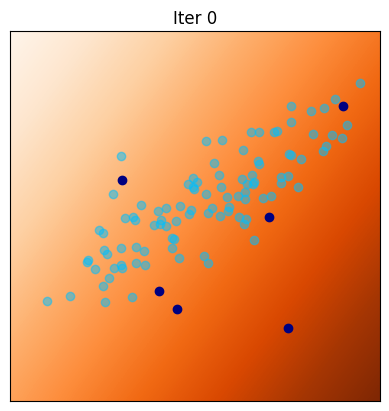

[100/1000], -0.040435


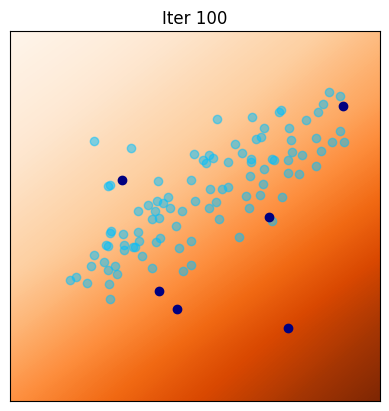

[200/1000], -0.074933


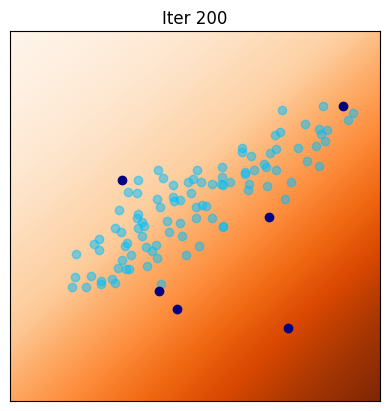

[300/1000], -0.068789


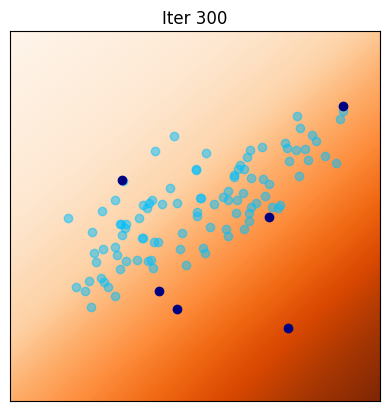

[400/1000], -0.072703


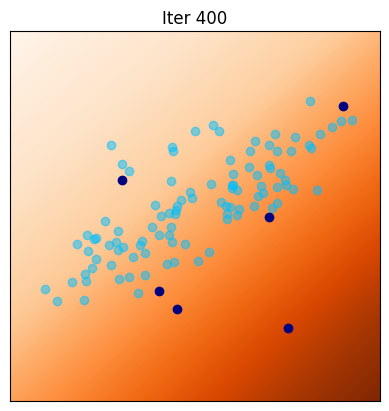

[500/1000], -0.060780


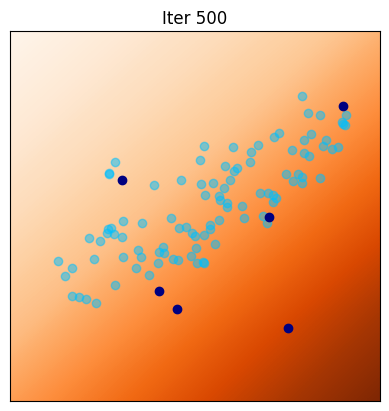

[600/1000], -0.077234


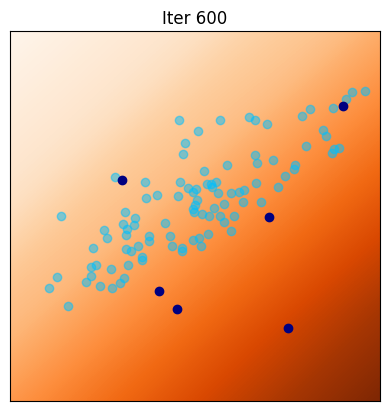

[700/1000], -0.075163


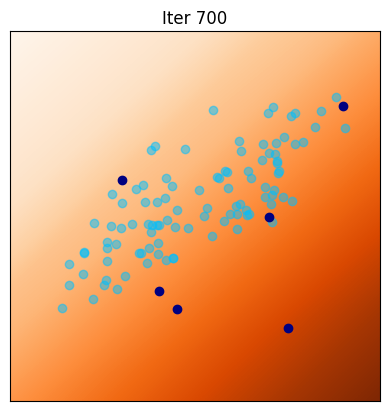

[800/1000], -0.081786


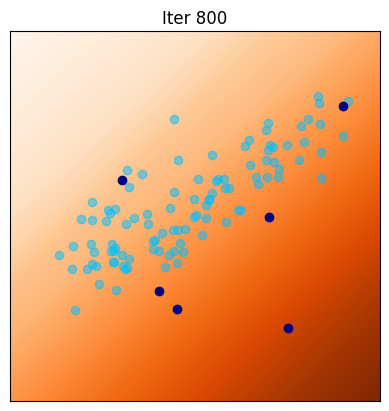

[900/1000], -0.074505


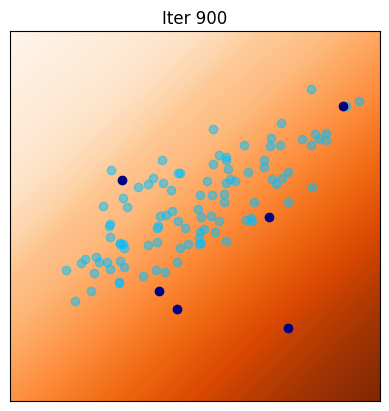

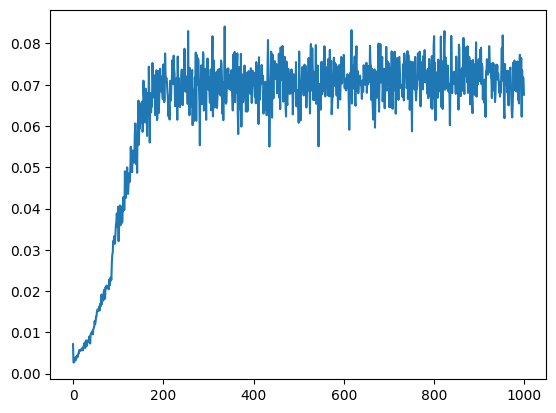

In [ ]:
torch.manual_seed(1)  # initialize random seed for reproducibility

# fix one generator
G = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)

# parameters for discriminator optimization
lrdisc = 0.002
beta_1 = 0.5
beta_2 = 0.999
niterD=1000

clip_value = .2

D = Discriminator(n_in=d, n_hid=10).to(device)
optimD = optim.Adam(D.parameters(), lr=lrdisc, betas=(beta_1, beta_2))

iter_display = 100  # display current configuration each iter_display iteration

# Lists to keep track of progress
Dlosses = []

for iter in range(0,niterD):

    ### UPDATE OF D ###
    optimD.zero_grad()

    ### ... ###
    z = torch.randn(b, n_in, device=device)
    x_fake = G(z)
    D_fake = D(x_fake)
    D_real = D(y)

    Dloss = -(torch.mean(D_real) - torch.mean(D_fake))

    ### ... ###
    Dloss.backward()
    optimD.step()
    ### ... Weight Clipping ... ###
    for p in D.parameters():
      p.data.clamp_(-clip_value,clip_value)
    ### SAVE LOSS ###
    Dlosst = Dloss.item()
    Dlosses.append(-Dlosst)

    if(iter%iter_display == 0):
        print('[%d/%d], %f' % (iter, niterD, Dlosst))
        Dxgrid = D(xgrid).detach().cpu().numpy().reshape(nr,nc)
        x = G(z)
        xd = x.detach().squeeze(1)
        strtitle = 'Iter '+str(iter)
        fig = plt.figure(dpi=100)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(Dxgrid,cmap = 'Oranges', extent=extent)  # discriminator
        plt.scatter(xd[:, 0].cpu(), xd[:,1].cpu(),c='deepskyblue',alpha=.5)
        plt.scatter(y[:, 0].cpu(), y[:,1].cpu(),c='navy')
        plt.title(strtitle)
        plt.show()

plt.plot(Dlosses)

## Estimate the Lipschitz constant of the discriminator

The following function computes a lower bound of the Lipschitz constant of $D$ on points that are interpolated between $x$ and $y$.

NB: If $x$ and $y$ do not have the same number of points, we discard the last points.
In comment, we give an alternative code that allows to compute all segments $[x_i, y_j]$ (but it is, of course, slower that just computing segments $[x_i, y_i]$).

In [ ]:
def lipconstant(D,x,y):
    b = x.shape[0]
    n = y.shape[0]
    # shrink vectors if they are too large
    if n>b:
        y = y[0:b,:]
        n = b
    else:
        x = x[0:n,:]
        b = n
    # compute interpolated points
    alpha = torch.rand((b,1),device=device)
    interp = alpha * y + (1 - alpha) * x
    interp.requires_grad_()

    # Calculate probability of interpolated examples
    Di = D(interp).view(-1)

    # Calculate gradients of probabilities with respect to examples
    gradout = torch.ones(Di.size()).to(device)
    gradients = torch.autograd.grad(outputs=Di, inputs=interp, grad_outputs=gradout,
       create_graph=True, retain_graph=True)[0]

    # Derivatives of the gradient close to 0 can cause problems because of
    # the square root, so manually calculate norm and add epsilon
    gradients_norm = torch.sqrt(torch.sum(gradients ** 2, dim=1))

    # Return gradient penalty
    return torch.mean(gradients_norm)

#     # Calculate interpolation
#     b = x.shape[0]
#     n = y.shape[0]
#     alpha = torch.rand((b,n,1),device=device)
#     interp = (alpha * y[None,:,:] + (1 - alpha) * x[:,None,:]).flatten(end_dim=1)
#     interp.requires_grad_()


QUESTION: Use this function to examine the Lipschitz constant of the final discriminator obtained above with weight clipping.


In [ ]:
### ... ###

x_fake = G(z)

# Calculate Lipschitz constant
lip_const = lipconstant(D, x_fake, y)

print("Lipschitz Constant of the Discriminator:", lip_const.item())

Lipschitz Constant of the Discriminator: 0.5418023467063904


## Gradient Penalty

QUESTION: Implement a function computing the gradient penalty of a discriminator $D$ on points $X$ that are randomly interpolated between $x$ and $y$:
$$ GP(D) = \mathbb{E}\left[ \Big(\|\nabla D(X)\| - 1 \Big)^2 \right] .$$
In pratice you will use
$$\|\nabla D(X)\| \approx \sqrt{\|\nabla D (X)\|_2^2 + 10^{-12} } $$
to avoid numerical instability.

In [ ]:
def gradient_penalty(D,x,y):
    b = x.shape[0]
    n = y.shape[0]
    # shrink vectors if they are too large
    if n>b:
        y = y[0:b,:]
        n = b
    else:
        x = x[0:n,:]
        b = n
    # compute interpolated points
    alpha = torch.rand((b,1),device=device)
    interp = (alpha * y + (1 - alpha) * x)
    interp.requires_grad_()

#     # Calculate interpolation
#     b = x.shape[0]
#     n = y.shape[0]
#     alpha = torch.rand((b,n,1),device=device)
#     interp = (alpha * y[None,:,:] + (1 - alpha) * x[:,None,:]).flatten(end_dim=1)
#     interp.requires_grad_()

    # Calculate probability of interpolated examples
    Di = D(interp).view(-1)

    # Calculate gradients of probabilities with respect to examples
    gradout = torch.ones(Di.size()).to(device)
    gradients = torch.autograd.grad(outputs=Di, inputs=interp, grad_outputs=gradout,
       create_graph=True, retain_graph=True)[0]

    # Derivatives of the gradient close to 0 can cause problems because of
    # the square root, so manually calculate norm and add epsilon
    gradients_norm = torch.sqrt(torch.sum(gradients ** 2, dim=1) + 1e-12)

    # Return gradient penalty
    return ((gradients_norm - 1) ** 2).mean()
#     return ((gradients_norm - 1) ** 2*(gradients_norm>1)).mean()

print(gradient_penalty(D,x,y))

tensor(0.1699, grad_fn=<MeanBackward0>)


## Discriminator training with Gradient Penalty

QUESTION: Complete the following code at the blocks ###...###.

Adjust the weight of the gradient penalty (parameter `gpw`) to get a Lipschitz constant $\approx 1$.

[0/1000], Dloss=8.5438, Lip(D)=0.0817


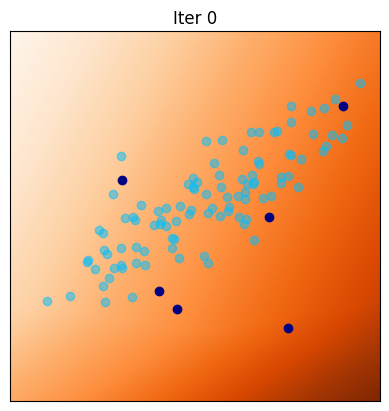

[100/1000], Dloss=0.1342, Lip(D)=1.0271


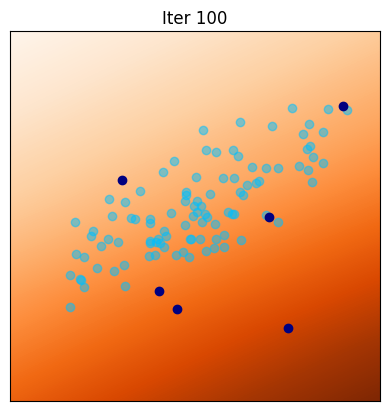

[200/1000], Dloss=-0.0890, Lip(D)=0.9870


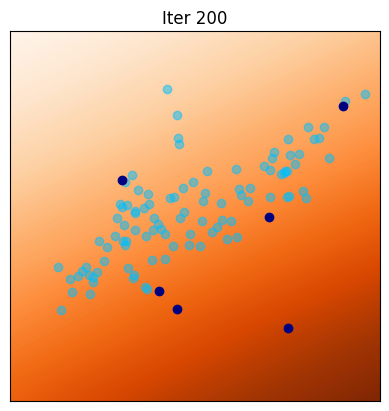

[300/1000], Dloss=-0.0907, Lip(D)=0.9973


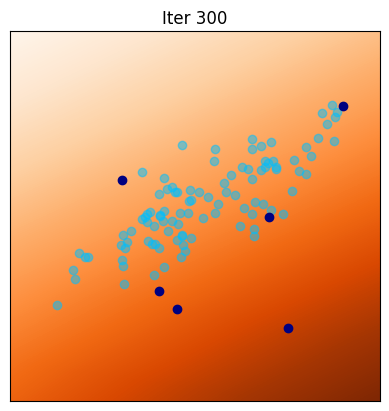

[400/1000], Dloss=-0.0951, Lip(D)=0.9989


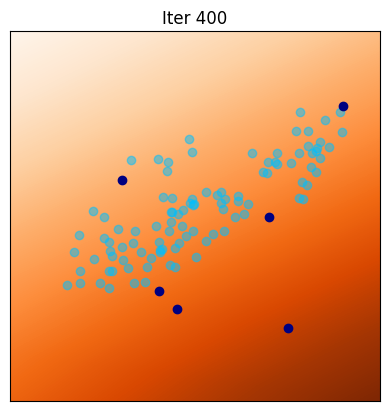

[500/1000], Dloss=-0.1198, Lip(D)=1.0106


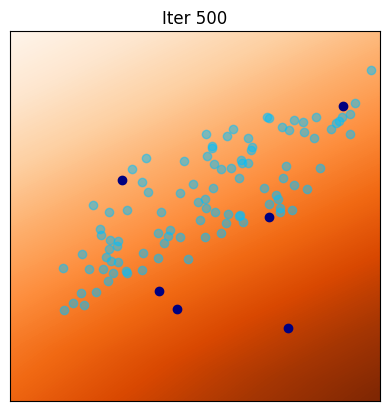

[600/1000], Dloss=-0.1128, Lip(D)=1.0047


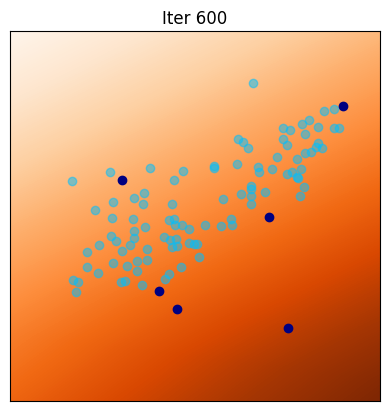

[700/1000], Dloss=-0.1194, Lip(D)=1.0068


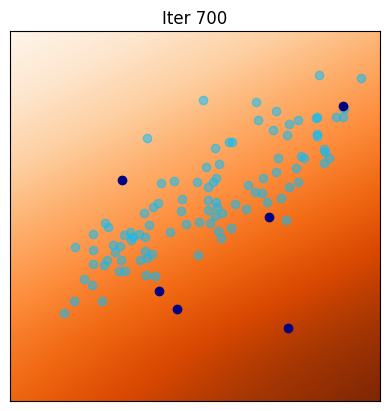

[800/1000], Dloss=-0.1280, Lip(D)=1.0043


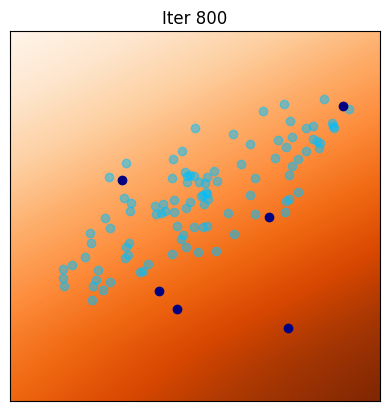

[900/1000], Dloss=-0.1198, Lip(D)=1.0092


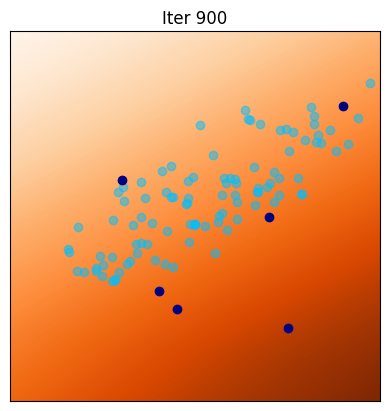

Final estimated Lipschitz constant =  1.0068317651748657


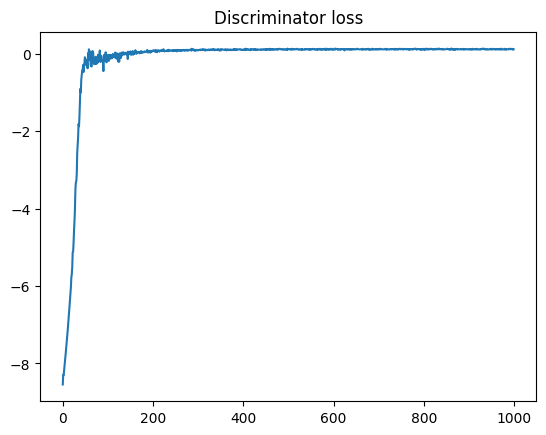

In [ ]:
torch.manual_seed(1)  # initialize random seed for reproducibility

# Initialize generators and discriminators
G = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
D = Discriminator(n_in=d, n_hid=10).to(device)

# parameters for training
lrdisc = 0.002
beta_1 = 0.5
beta_2 = 0.999
niterD=1000
gpw = 10       # parameter for gradient penalty

optimD = optim.Adam(D.parameters(), lr=lrdisc, betas=(beta_1, beta_2))


iter_display = 100  # display current configuration each iter_display iteration

# Lists to keep track of progress
Dlosses = []

for iter in range(0,niterD):

    ### UPDATE OF D ###

    ### ... ###
    optimD.zero_grad()

    # Generate fake data
    z = torch.randn(b, n_in, device=device)
    x_fake = G(z)

    # Calculate WGAN loss
    D_real = D(y)
    D_fake = D(x_fake)
    Dloss = -(torch.mean(D_real) - torch.mean(D_fake))

    # Gradient Penalty
    gp = gradient_penalty(D, x_fake, y)
    Dloss += gp * gpw

    # Backpropagation and optimization
    Dloss.backward()
    optimD.step()
    ### SAVE LOSS ###
    Dlosst = Dloss.item()
    Dlosses.append(-Dlosst)

    if(iter%iter_display == 0):
        print('[%d/%d], Dloss=%.4f, Lip(D)=%.4f' % (iter, niterD, Dlosst,lipconstant(D,x,y).item()))
        Dxgrid = D(xgrid).detach().cpu().numpy().reshape(nr,nc)
        x = G(z)
        xd = x.detach().squeeze(1)
        strtitle = 'Iter '+str(iter)
        fig = plt.figure(dpi=100)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(Dxgrid,cmap = 'Oranges', extent=extent)  # discriminator
        plt.scatter(xd[:, 0].cpu(), xd[:,1].cpu(),c='deepskyblue',alpha=.5)
        plt.scatter(y[:, 0].cpu(), y[:,1].cpu(),c='navy')
        plt.title(strtitle)
        plt.show()

print('Final estimated Lipschitz constant = ',lipconstant(D,x,y).item())

plt.figure(dpi=100)
plt.plot(Dlosses)
plt.title('Discriminator loss')
plt.show()

## WGAN-GP training

QUESTION: Complete the following code in order to train simultaneously the generator and discriminator.

You will alternate `niterD` iterations on the discriminator and `niterG` iterations of the discriminator.

[1/100] 	Loss_D: -0.1772	Loss_G: -1.7357	Lip(D)=1.9167
[2/100] 	Loss_D: -0.1457	Loss_G: -1.0743	Lip(D)=1.5458
[3/100] 	Loss_D: -0.1768	Loss_G: -2.3139	Lip(D)=1.5967
[4/100] 	Loss_D: -0.1088	Loss_G: -4.3816	Lip(D)=1.1480
[5/100] 	Loss_D: -0.1132	Loss_G: -9.1704	Lip(D)=1.2491


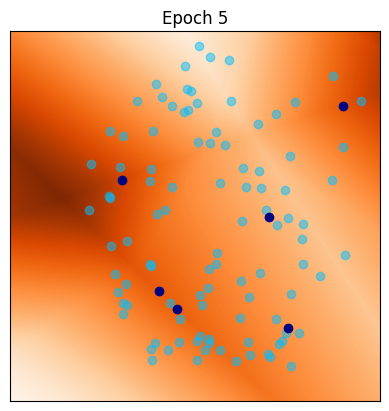

[6/100] 	Loss_D: -0.1831	Loss_G: -12.8906	Lip(D)=1.6762
[7/100] 	Loss_D: -0.1584	Loss_G: -13.7936	Lip(D)=1.3650
[8/100] 	Loss_D: -0.0387	Loss_G: -14.4660	Lip(D)=1.3766
[9/100] 	Loss_D: -0.1135	Loss_G: -16.5674	Lip(D)=1.3103
[10/100] 	Loss_D: -0.1161	Loss_G: -18.1562	Lip(D)=1.3588


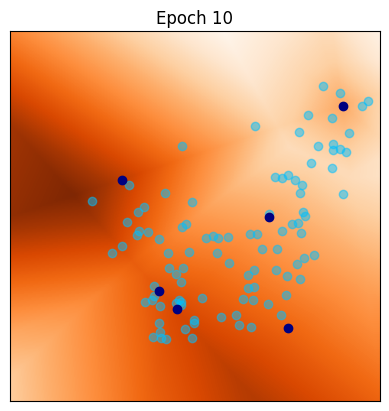

[11/100] 	Loss_D: -0.1165	Loss_G: -16.5484	Lip(D)=1.2618
[12/100] 	Loss_D: -0.1194	Loss_G: -22.9229	Lip(D)=1.4817
[13/100] 	Loss_D: -0.1199	Loss_G: -26.4842	Lip(D)=1.4311
[14/100] 	Loss_D: -0.1286	Loss_G: -28.4904	Lip(D)=1.1531
[15/100] 	Loss_D: -0.1473	Loss_G: -31.1420	Lip(D)=1.6756


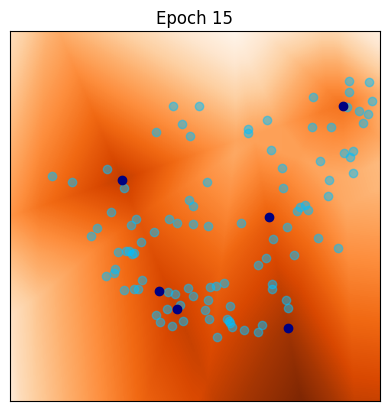

[16/100] 	Loss_D: -0.1138	Loss_G: -28.9682	Lip(D)=1.7160
[17/100] 	Loss_D: -0.1455	Loss_G: -33.5703	Lip(D)=1.6130
[18/100] 	Loss_D: -0.0740	Loss_G: -36.6449	Lip(D)=1.7331
[19/100] 	Loss_D: -0.0840	Loss_G: -36.3444	Lip(D)=1.3416
[20/100] 	Loss_D: -0.1026	Loss_G: -36.3645	Lip(D)=1.6665


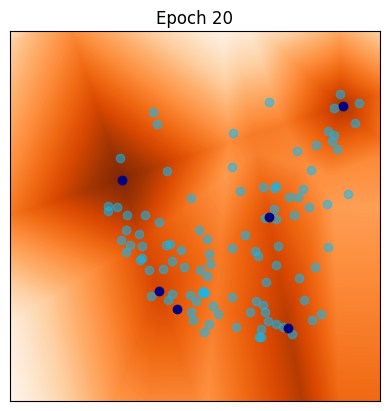

[21/100] 	Loss_D: -0.1109	Loss_G: -35.4880	Lip(D)=1.2868
[22/100] 	Loss_D: -0.1038	Loss_G: -36.2246	Lip(D)=1.3320
[23/100] 	Loss_D: -0.0991	Loss_G: -38.5405	Lip(D)=1.1427
[24/100] 	Loss_D: -0.1016	Loss_G: -38.0337	Lip(D)=1.1335
[25/100] 	Loss_D: -0.1007	Loss_G: -37.8770	Lip(D)=1.2383


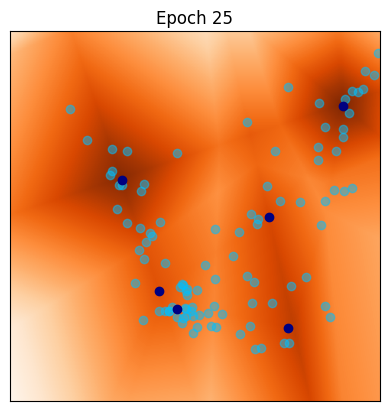

[26/100] 	Loss_D: -0.1071	Loss_G: -39.4078	Lip(D)=1.3214
[27/100] 	Loss_D: -0.1026	Loss_G: -40.2870	Lip(D)=1.6289
[28/100] 	Loss_D: -0.1205	Loss_G: -42.7559	Lip(D)=1.5201
[29/100] 	Loss_D: -0.0946	Loss_G: -43.3687	Lip(D)=1.6135
[30/100] 	Loss_D: -0.0829	Loss_G: -42.9607	Lip(D)=1.4041


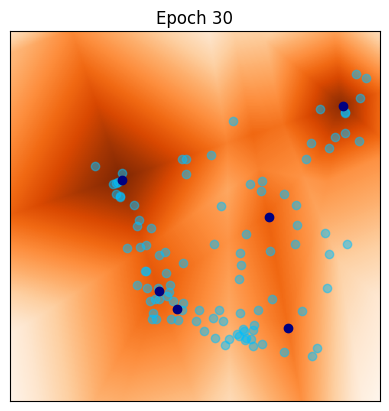

[31/100] 	Loss_D: -0.0816	Loss_G: -46.2477	Lip(D)=1.4186
[32/100] 	Loss_D: -0.1125	Loss_G: -48.2242	Lip(D)=1.1541
[33/100] 	Loss_D: -0.1154	Loss_G: -45.4768	Lip(D)=1.4038
[34/100] 	Loss_D: -0.0859	Loss_G: -47.6623	Lip(D)=1.2175
[35/100] 	Loss_D: -0.1140	Loss_G: -51.3372	Lip(D)=1.2720


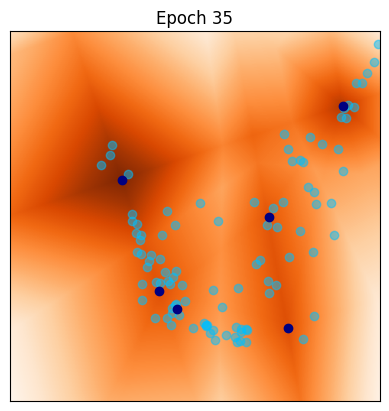

[36/100] 	Loss_D: -0.1175	Loss_G: -52.9216	Lip(D)=1.2711
[37/100] 	Loss_D: -0.0877	Loss_G: -57.1835	Lip(D)=1.1287
[38/100] 	Loss_D: -0.0714	Loss_G: -54.5920	Lip(D)=1.2620
[39/100] 	Loss_D: -0.0871	Loss_G: -57.0765	Lip(D)=1.2555
[40/100] 	Loss_D: -0.0865	Loss_G: -60.1080	Lip(D)=1.3720


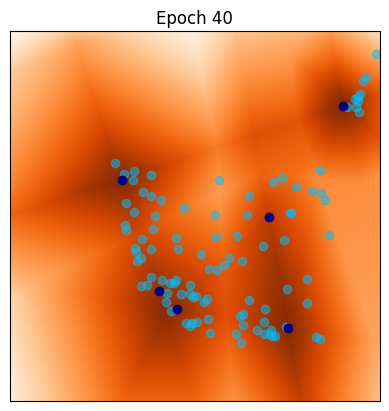

[41/100] 	Loss_D: -0.1215	Loss_G: -63.6518	Lip(D)=1.4160
[42/100] 	Loss_D: -0.0951	Loss_G: -66.1828	Lip(D)=1.1595
[43/100] 	Loss_D: -0.0783	Loss_G: -65.6923	Lip(D)=1.3382
[44/100] 	Loss_D: -0.0888	Loss_G: -67.2925	Lip(D)=1.2857
[45/100] 	Loss_D: -0.1047	Loss_G: -69.3361	Lip(D)=1.1725


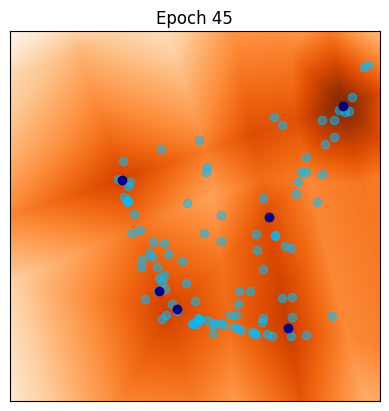

[46/100] 	Loss_D: -0.0939	Loss_G: -74.8676	Lip(D)=1.1501
[47/100] 	Loss_D: -0.0813	Loss_G: -76.2514	Lip(D)=1.2012
[48/100] 	Loss_D: -0.0969	Loss_G: -79.0367	Lip(D)=1.4163
[49/100] 	Loss_D: -0.0904	Loss_G: -81.0240	Lip(D)=1.4018
[50/100] 	Loss_D: -0.0736	Loss_G: -83.7038	Lip(D)=1.2920


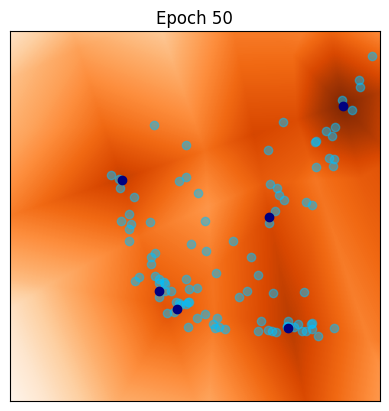

[51/100] 	Loss_D: -0.0930	Loss_G: -88.3173	Lip(D)=1.4114
[52/100] 	Loss_D: -0.0985	Loss_G: -89.5722	Lip(D)=1.2540
[53/100] 	Loss_D: -0.0812	Loss_G: -89.3820	Lip(D)=1.4711
[54/100] 	Loss_D: -0.0835	Loss_G: -92.5271	Lip(D)=1.3946
[55/100] 	Loss_D: -0.1076	Loss_G: -94.3199	Lip(D)=1.2598


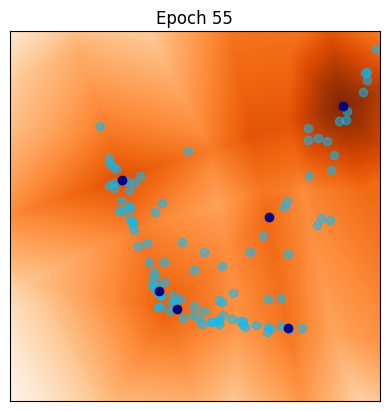

[56/100] 	Loss_D: -0.0782	Loss_G: -97.7487	Lip(D)=1.2766
[57/100] 	Loss_D: -0.0855	Loss_G: -96.0252	Lip(D)=1.3833
[58/100] 	Loss_D: -0.0827	Loss_G: -97.9100	Lip(D)=1.4345
[59/100] 	Loss_D: -0.1094	Loss_G: -102.1745	Lip(D)=1.3381
[60/100] 	Loss_D: -0.0941	Loss_G: -101.9165	Lip(D)=1.3689


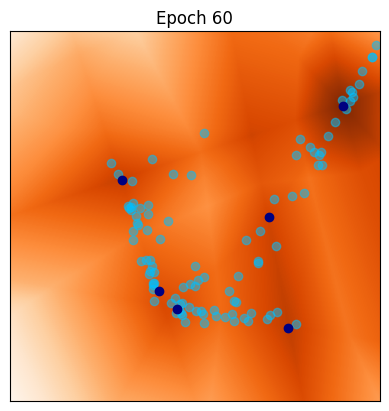

[61/100] 	Loss_D: -0.0753	Loss_G: -100.9798	Lip(D)=1.6291
[62/100] 	Loss_D: -0.0993	Loss_G: -101.3231	Lip(D)=1.3770
[63/100] 	Loss_D: -0.0967	Loss_G: -106.2993	Lip(D)=1.3283
[64/100] 	Loss_D: -0.1043	Loss_G: -103.9089	Lip(D)=1.3034
[65/100] 	Loss_D: -0.0727	Loss_G: -105.7475	Lip(D)=1.4884


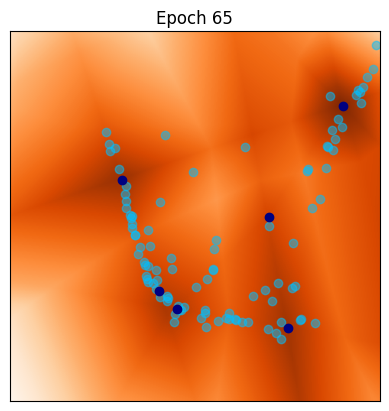

[66/100] 	Loss_D: -0.0862	Loss_G: -104.5823	Lip(D)=1.2522
[67/100] 	Loss_D: -0.0899	Loss_G: -105.9291	Lip(D)=1.4505
[68/100] 	Loss_D: -0.0764	Loss_G: -107.9012	Lip(D)=1.2581
[69/100] 	Loss_D: -0.0679	Loss_G: -105.3437	Lip(D)=1.3119
[70/100] 	Loss_D: -0.0769	Loss_G: -108.0091	Lip(D)=1.1637


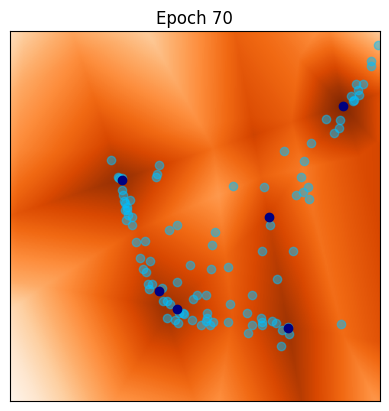

[71/100] 	Loss_D: -0.0416	Loss_G: -111.0913	Lip(D)=1.3579
[72/100] 	Loss_D: -0.0949	Loss_G: -113.3566	Lip(D)=1.1907
[73/100] 	Loss_D: -0.0649	Loss_G: -109.7115	Lip(D)=1.4066
[74/100] 	Loss_D: -0.0688	Loss_G: -111.6597	Lip(D)=1.3544
[75/100] 	Loss_D: -0.0892	Loss_G: -110.1843	Lip(D)=1.1683


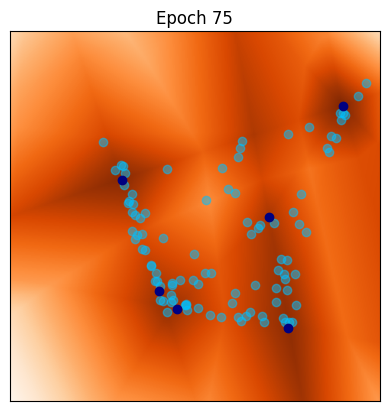

[76/100] 	Loss_D: -0.0951	Loss_G: -114.1855	Lip(D)=1.3978
[77/100] 	Loss_D: -0.0699	Loss_G: -113.2174	Lip(D)=1.3950
[78/100] 	Loss_D: -0.0727	Loss_G: -114.5656	Lip(D)=1.1907
[79/100] 	Loss_D: -0.0799	Loss_G: -119.6408	Lip(D)=1.3399
[80/100] 	Loss_D: -0.0726	Loss_G: -115.9303	Lip(D)=1.2705


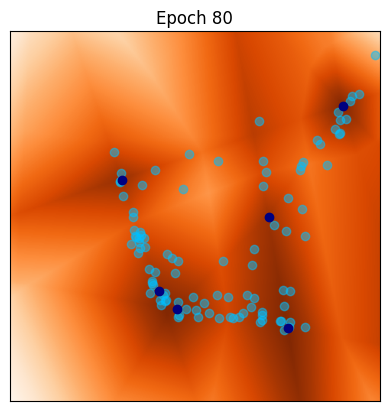

[81/100] 	Loss_D: -0.0849	Loss_G: -117.8910	Lip(D)=1.3084
[82/100] 	Loss_D: -0.0307	Loss_G: -119.2382	Lip(D)=1.3260
[83/100] 	Loss_D: -0.0635	Loss_G: -119.7621	Lip(D)=1.6004
[84/100] 	Loss_D: -0.0852	Loss_G: -117.9119	Lip(D)=1.2071
[85/100] 	Loss_D: -0.0673	Loss_G: -114.5356	Lip(D)=1.4263


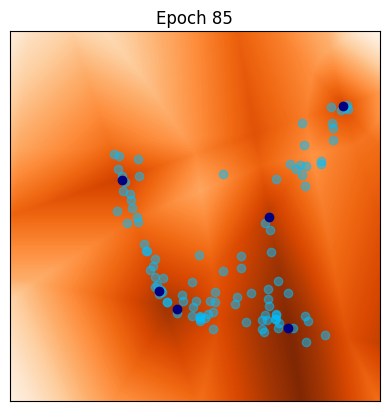

[86/100] 	Loss_D: -0.0266	Loss_G: -123.3508	Lip(D)=1.1410
[87/100] 	Loss_D: -0.0493	Loss_G: -126.2786	Lip(D)=1.0388
[88/100] 	Loss_D: -0.0539	Loss_G: -122.1054	Lip(D)=1.1133
[89/100] 	Loss_D: -0.0749	Loss_G: -123.2179	Lip(D)=1.2144
[90/100] 	Loss_D: -0.0893	Loss_G: -125.7250	Lip(D)=1.4223


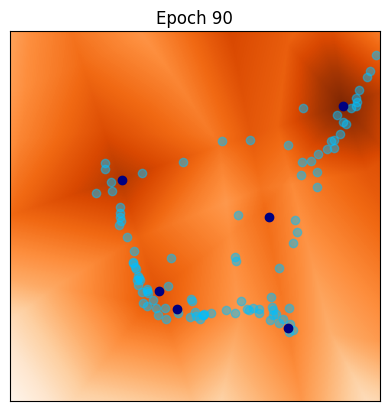

[91/100] 	Loss_D: -0.0694	Loss_G: -120.0981	Lip(D)=1.3213
[92/100] 	Loss_D: -0.0549	Loss_G: -118.4726	Lip(D)=1.4853
[93/100] 	Loss_D: -0.0773	Loss_G: -127.4919	Lip(D)=1.3811
[94/100] 	Loss_D: -0.1176	Loss_G: -124.8671	Lip(D)=1.6392
[95/100] 	Loss_D: -0.0794	Loss_G: -105.8126	Lip(D)=1.4179


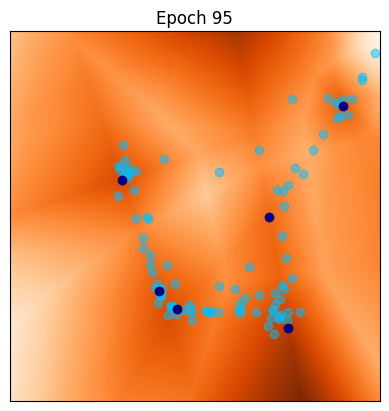

[96/100] 	Loss_D: -0.0709	Loss_G: -111.9552	Lip(D)=1.3138
[97/100] 	Loss_D: -0.0703	Loss_G: -112.1493	Lip(D)=1.1860
[98/100] 	Loss_D: -0.0452	Loss_G: -117.1514	Lip(D)=1.4376
[99/100] 	Loss_D: -0.0770	Loss_G: -120.5210	Lip(D)=1.2258


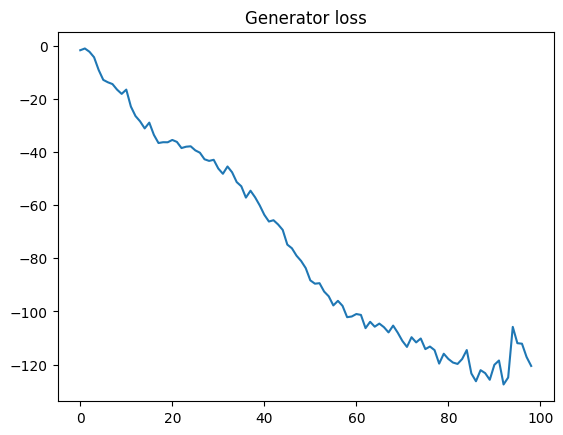

<All keys matched successfully>

In [ ]:
## parameters for training
n_epochs = 100
niterD=1000
niterG=10
gpw = .1

lr = 0.002      # learning rate for generator
lrdisc = 0.002  # learning rate for discriminator
beta_1 = 0.5
beta_2 = 0.999

torch.manual_seed(1)  # initialize random seed for reproducibility

# Initialize generators and discriminators
G = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
optimG = optim.Adam(G.parameters(), lr=lr)

D = Discriminator(n_in=d, n_hid=10).to(device)
optimD = optim.Adam(D.parameters(), lr=lrdisc, betas=(beta_1, beta_2))


Glosses = []
Dlosses = []

iter_display = 5

# Main loop
for epoch in range(1,n_epochs):

    ############################
    ### Train discriminator (niterD iterations)
    ############################

    for iter in range(0,niterD):
        optimD.zero_grad()

        # Generate fake data
        z = torch.randn(b, n_in, device=device)
        x_fake = G(z)

        # Calculate WGAN loss
        D_real = D(y)
        D_fake = D(x_fake)
        Dloss = -(torch.mean(D_real) - torch.mean(D_fake))

        # Gradient Penalty
        gp = gradient_penalty(D, x_fake, y)
        Dloss += gp * gpw

        # Backpropagation and optimization
        Dloss.backward()
        optimD.step()

    ############################
    ### Train generator (niterG iterations)
    ############################
    for iter in range(0,niterG):
        optimG.zero_grad()

        # Generate fake data
        z = torch.randn(b, n_in, device=device)
        x_fake = G(z)

        # Calculate WGAN loss for generator
        D_fake = D(x_fake)
        Gloss = -torch.mean(D_fake)

        # Backpropagation and optimization
        Gloss.backward()
        optimG.step()

    # Output training stats
    print('[%d/%d] \tLoss_D: %.4f\tLoss_G: %.4f\tLip(D)=%.4f'
      % (epoch, n_epochs, Dloss.item(), Gloss.item(),lipconstant(D,x,y).item()))
    Glosses.append(Gloss.item())
    Dlosses.append(Dloss.item())

    if(epoch % iter_display == 0):
        Dxgrid = D(xgrid).detach().cpu().numpy().reshape(nr,nc)
        z = torch.randn(b, n_in, device=device)
        x = G(z)
        xd = x.detach().squeeze(1)
        strtitle = 'Epoch '+str(epoch)
        fig = plt.figure(dpi=100)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(Dxgrid,cmap = 'Oranges', extent=extent)
        plt.scatter(xd[:, 0].cpu(), xd[:,1].cpu(),c='deepskyblue',alpha=.5)
        plt.scatter(y[:, 0].cpu(), y[:,1].cpu(),c='navy')
        plt.title(strtitle)
        plt.show()


plt.figure(dpi=100)
plt.plot(Glosses)
plt.title('Generator loss')
plt.show()

# Save final generator for later use
wgan = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
wgan.load_state_dict(G.state_dict())

## Sensitivy to hyper-parameters

QUESTION: Repeat the WGAN learning experiment, by changing the parameters of the optimization (learning rates, number of updates of D and G, etc).

From your experiments, can you draw a few recommendations for stable training?

We can conclude a few things from our experiments.

It seems that for the learning rates, lower learning rates are better for the generator as they tend to stabilize training since the generator is less likely to produce unrealistic samples too quickly.
For the discriminator, slightly higher learning rates can help the discriminator give good results to the output of the the generator.

Additionally, updating the discriminator more frequently than the generator (I used a ration of around 5 to 1, but perhaps some other values are better) helps the results given by the discriminator.

Finally, for the gradient penalty weight, 10 seems to give good results.

[1/100] 	Loss_D: -0.1772	Loss_G: -1.7357	Lip(D)=1.7327
[2/100] 	Loss_D: -0.1457	Loss_G: -1.0743	Lip(D)=1.5678
[3/100] 	Loss_D: -0.1768	Loss_G: -2.3139	Lip(D)=1.5707
[4/100] 	Loss_D: -0.1088	Loss_G: -4.3816	Lip(D)=1.4141
[5/100] 	Loss_D: -0.1132	Loss_G: -9.1704	Lip(D)=1.2438


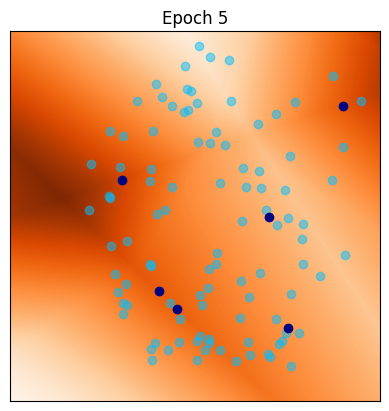

[6/100] 	Loss_D: -0.1831	Loss_G: -12.8906	Lip(D)=1.6762
[7/100] 	Loss_D: -0.1584	Loss_G: -13.7936	Lip(D)=1.3650
[8/100] 	Loss_D: -0.0387	Loss_G: -14.4660	Lip(D)=1.3766
[9/100] 	Loss_D: -0.1135	Loss_G: -16.5674	Lip(D)=1.3103
[10/100] 	Loss_D: -0.1161	Loss_G: -18.1562	Lip(D)=1.3588


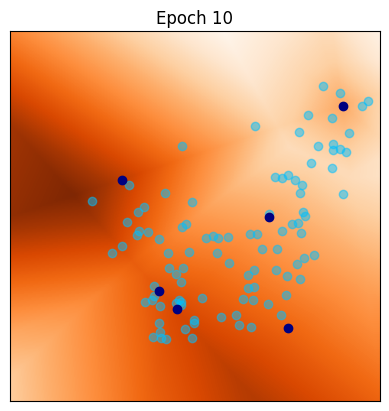

[11/100] 	Loss_D: -0.1165	Loss_G: -16.5484	Lip(D)=1.2618
[12/100] 	Loss_D: -0.1194	Loss_G: -22.9229	Lip(D)=1.4817
[13/100] 	Loss_D: -0.1199	Loss_G: -26.4842	Lip(D)=1.4311
[14/100] 	Loss_D: -0.1286	Loss_G: -28.4904	Lip(D)=1.1531
[15/100] 	Loss_D: -0.1473	Loss_G: -31.1420	Lip(D)=1.6756


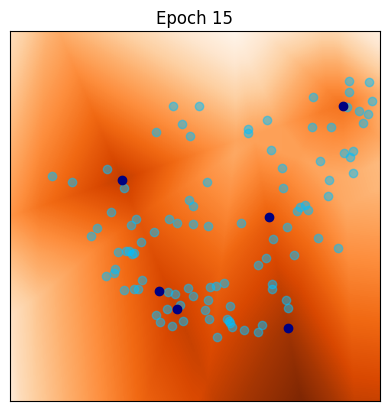

[16/100] 	Loss_D: -0.1138	Loss_G: -28.9682	Lip(D)=1.7160
[17/100] 	Loss_D: -0.1455	Loss_G: -33.5703	Lip(D)=1.6130
[18/100] 	Loss_D: -0.0740	Loss_G: -36.6449	Lip(D)=1.7331
[19/100] 	Loss_D: -0.0840	Loss_G: -36.3444	Lip(D)=1.3416
[20/100] 	Loss_D: -0.1026	Loss_G: -36.3645	Lip(D)=1.6665


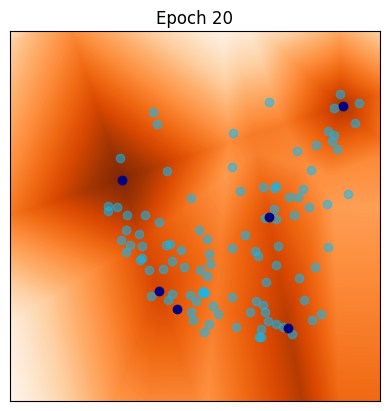

[21/100] 	Loss_D: -0.1109	Loss_G: -35.4880	Lip(D)=1.2868
[22/100] 	Loss_D: -0.1038	Loss_G: -36.2246	Lip(D)=1.3320
[23/100] 	Loss_D: -0.0991	Loss_G: -38.5405	Lip(D)=1.1427
[24/100] 	Loss_D: -0.1016	Loss_G: -38.0337	Lip(D)=1.1335
[25/100] 	Loss_D: -0.1007	Loss_G: -37.8770	Lip(D)=1.2383


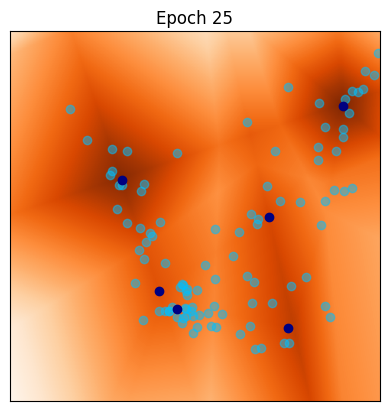

[26/100] 	Loss_D: -0.1071	Loss_G: -39.4078	Lip(D)=1.3214
[27/100] 	Loss_D: -0.1026	Loss_G: -40.2870	Lip(D)=1.6289
[28/100] 	Loss_D: -0.1205	Loss_G: -42.7559	Lip(D)=1.5201
[29/100] 	Loss_D: -0.0946	Loss_G: -43.3687	Lip(D)=1.6135
[30/100] 	Loss_D: -0.0829	Loss_G: -42.9607	Lip(D)=1.4041


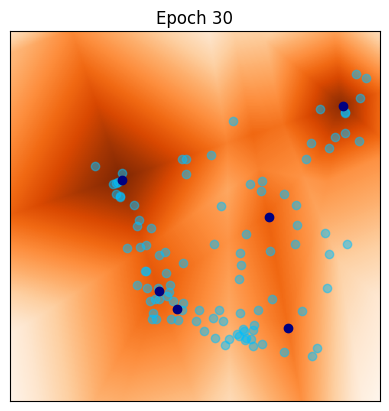

[31/100] 	Loss_D: -0.0816	Loss_G: -46.2477	Lip(D)=1.4186
[32/100] 	Loss_D: -0.1125	Loss_G: -48.2242	Lip(D)=1.1541
[33/100] 	Loss_D: -0.1154	Loss_G: -45.4768	Lip(D)=1.4038
[34/100] 	Loss_D: -0.0859	Loss_G: -47.6623	Lip(D)=1.2175
[35/100] 	Loss_D: -0.1140	Loss_G: -51.3372	Lip(D)=1.2720


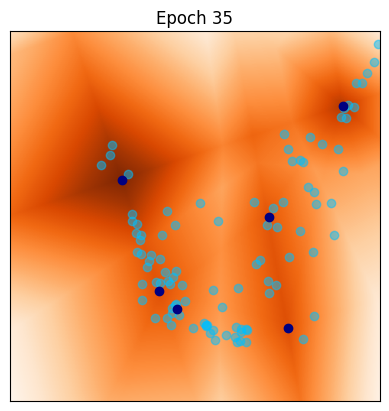

[36/100] 	Loss_D: -0.1175	Loss_G: -52.9216	Lip(D)=1.2711
[37/100] 	Loss_D: -0.0877	Loss_G: -57.1835	Lip(D)=1.1287
[38/100] 	Loss_D: -0.0714	Loss_G: -54.5920	Lip(D)=1.2620
[39/100] 	Loss_D: -0.0871	Loss_G: -57.0765	Lip(D)=1.2555
[40/100] 	Loss_D: -0.0865	Loss_G: -60.1080	Lip(D)=1.3720


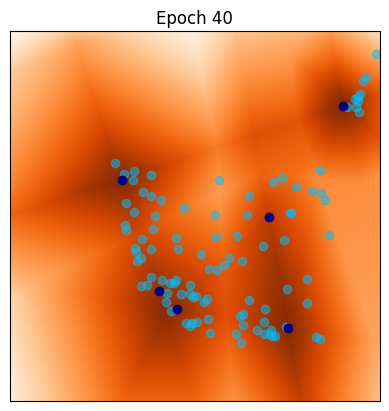

[41/100] 	Loss_D: -0.1215	Loss_G: -63.6518	Lip(D)=1.4160
[42/100] 	Loss_D: -0.0951	Loss_G: -66.1828	Lip(D)=1.1595
[43/100] 	Loss_D: -0.0783	Loss_G: -65.6923	Lip(D)=1.3382
[44/100] 	Loss_D: -0.0888	Loss_G: -67.2925	Lip(D)=1.2857
[45/100] 	Loss_D: -0.1047	Loss_G: -69.3361	Lip(D)=1.1725


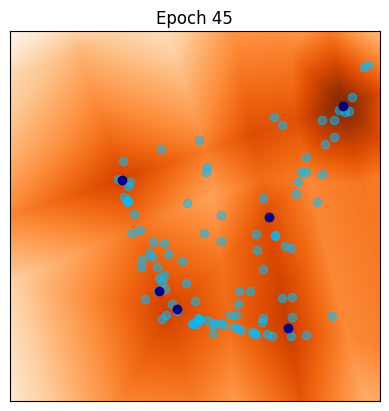

[46/100] 	Loss_D: -0.0939	Loss_G: -74.8676	Lip(D)=1.1501
[47/100] 	Loss_D: -0.0813	Loss_G: -76.2514	Lip(D)=1.2012
[48/100] 	Loss_D: -0.0969	Loss_G: -79.0367	Lip(D)=1.4163
[49/100] 	Loss_D: -0.0904	Loss_G: -81.0240	Lip(D)=1.4018
[50/100] 	Loss_D: -0.0736	Loss_G: -83.7038	Lip(D)=1.2920


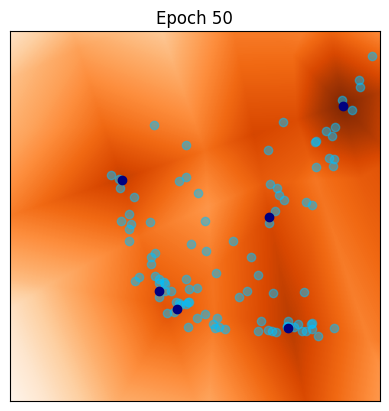

[51/100] 	Loss_D: -0.0930	Loss_G: -88.3173	Lip(D)=1.4114
[52/100] 	Loss_D: -0.0985	Loss_G: -89.5722	Lip(D)=1.2540
[53/100] 	Loss_D: -0.0812	Loss_G: -89.3820	Lip(D)=1.4711
[54/100] 	Loss_D: -0.0835	Loss_G: -92.5271	Lip(D)=1.3946
[55/100] 	Loss_D: -0.1076	Loss_G: -94.3199	Lip(D)=1.2598


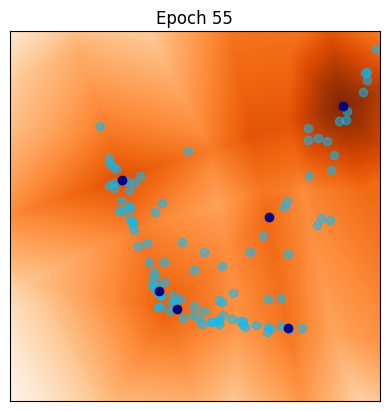

[56/100] 	Loss_D: -0.0782	Loss_G: -97.7487	Lip(D)=1.2766
[57/100] 	Loss_D: -0.0855	Loss_G: -96.0252	Lip(D)=1.3833
[58/100] 	Loss_D: -0.0827	Loss_G: -97.9100	Lip(D)=1.4345
[59/100] 	Loss_D: -0.1094	Loss_G: -102.1745	Lip(D)=1.3381
[60/100] 	Loss_D: -0.0941	Loss_G: -101.9165	Lip(D)=1.3689


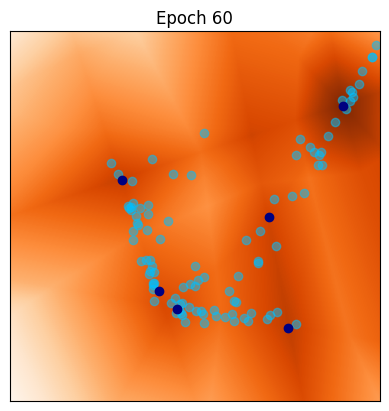

[61/100] 	Loss_D: -0.0753	Loss_G: -100.9798	Lip(D)=1.6291
[62/100] 	Loss_D: -0.0993	Loss_G: -101.3231	Lip(D)=1.3770
[63/100] 	Loss_D: -0.0967	Loss_G: -106.2993	Lip(D)=1.3283
[64/100] 	Loss_D: -0.1043	Loss_G: -103.9089	Lip(D)=1.3034
[65/100] 	Loss_D: -0.0727	Loss_G: -105.7475	Lip(D)=1.4884


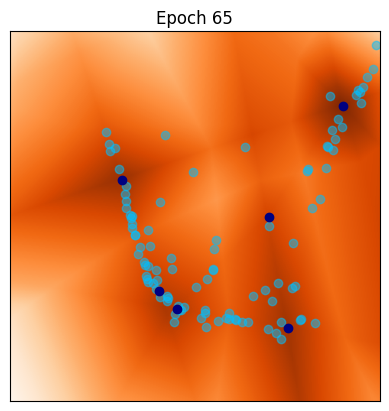

[66/100] 	Loss_D: -0.0862	Loss_G: -104.5823	Lip(D)=1.2522
[67/100] 	Loss_D: -0.0899	Loss_G: -105.9291	Lip(D)=1.4505
[68/100] 	Loss_D: -0.0764	Loss_G: -107.9012	Lip(D)=1.2581
[69/100] 	Loss_D: -0.0679	Loss_G: -105.3437	Lip(D)=1.3119
[70/100] 	Loss_D: -0.0769	Loss_G: -108.0091	Lip(D)=1.1637


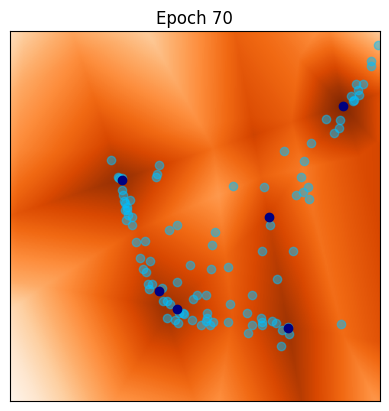

[71/100] 	Loss_D: -0.0416	Loss_G: -111.0913	Lip(D)=1.3579
[72/100] 	Loss_D: -0.0949	Loss_G: -113.3566	Lip(D)=1.1907
[73/100] 	Loss_D: -0.0649	Loss_G: -109.7115	Lip(D)=1.4066
[74/100] 	Loss_D: -0.0688	Loss_G: -111.6597	Lip(D)=1.3544
[75/100] 	Loss_D: -0.0892	Loss_G: -110.1843	Lip(D)=1.1683


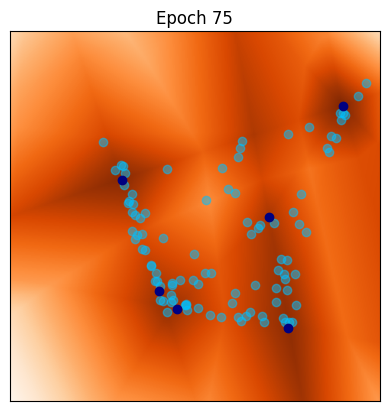

[76/100] 	Loss_D: -0.0951	Loss_G: -114.1855	Lip(D)=1.3978
[77/100] 	Loss_D: -0.0699	Loss_G: -113.2174	Lip(D)=1.3950
[78/100] 	Loss_D: -0.0727	Loss_G: -114.5656	Lip(D)=1.1907
[79/100] 	Loss_D: -0.0799	Loss_G: -119.6408	Lip(D)=1.3399
[80/100] 	Loss_D: -0.0726	Loss_G: -115.9303	Lip(D)=1.2705


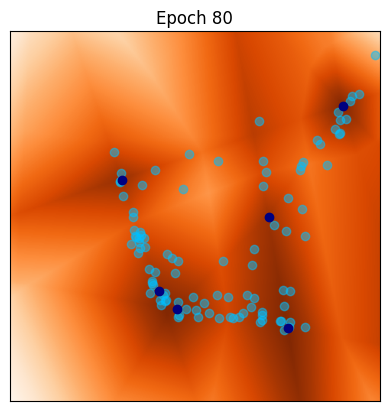

[81/100] 	Loss_D: -0.0849	Loss_G: -117.8910	Lip(D)=1.3084
[82/100] 	Loss_D: -0.0307	Loss_G: -119.2382	Lip(D)=1.3260
[83/100] 	Loss_D: -0.0635	Loss_G: -119.7621	Lip(D)=1.6004
[84/100] 	Loss_D: -0.0852	Loss_G: -117.9119	Lip(D)=1.2071
[85/100] 	Loss_D: -0.0673	Loss_G: -114.5356	Lip(D)=1.4263


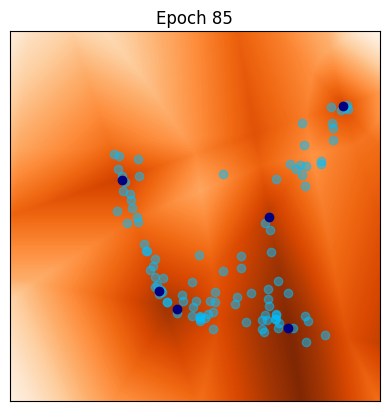

[86/100] 	Loss_D: -0.0266	Loss_G: -123.3508	Lip(D)=1.1410
[87/100] 	Loss_D: -0.0493	Loss_G: -126.2786	Lip(D)=1.0388
[88/100] 	Loss_D: -0.0539	Loss_G: -122.1054	Lip(D)=1.1133
[89/100] 	Loss_D: -0.0749	Loss_G: -123.2179	Lip(D)=1.2144
[90/100] 	Loss_D: -0.0893	Loss_G: -125.7250	Lip(D)=1.4223


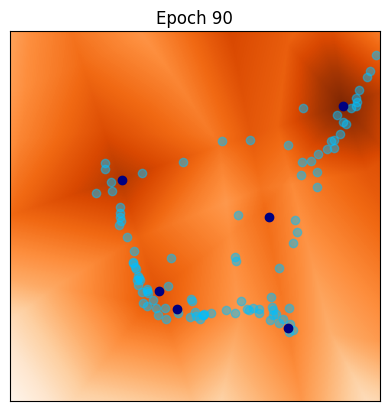

[91/100] 	Loss_D: -0.0694	Loss_G: -120.0981	Lip(D)=1.3213
[92/100] 	Loss_D: -0.0549	Loss_G: -118.4726	Lip(D)=1.4853
[93/100] 	Loss_D: -0.0773	Loss_G: -127.4919	Lip(D)=1.3811
[94/100] 	Loss_D: -0.1176	Loss_G: -124.8671	Lip(D)=1.6392
[95/100] 	Loss_D: -0.0794	Loss_G: -105.8126	Lip(D)=1.4179


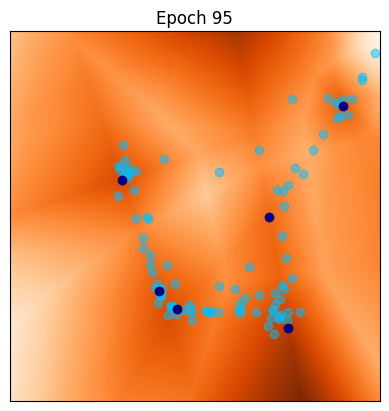

[96/100] 	Loss_D: -0.0709	Loss_G: -111.9552	Lip(D)=1.3138
[97/100] 	Loss_D: -0.0703	Loss_G: -112.1493	Lip(D)=1.1860
[98/100] 	Loss_D: -0.0452	Loss_G: -117.1514	Lip(D)=1.4376
[99/100] 	Loss_D: -0.0770	Loss_G: -120.5210	Lip(D)=1.2258


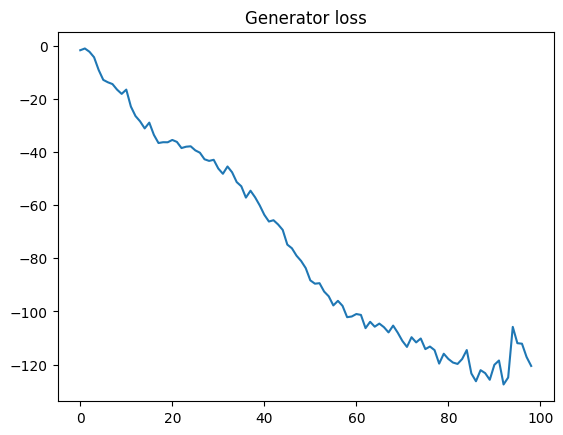

<All keys matched successfully>

In [ ]:
## parameters for training
n_epochs = 100
niterD=1000
niterG=10
gpw = .1

lr = 0.002      # learning rate for generator
lrdisc = 0.002  # learning rate for discriminator
beta_1 = 0.5
beta_2 = 0.999

torch.manual_seed(1)  # initialize random seed for reproducibility

# Initialize generators and discriminators
G = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
optimG = optim.Adam(G.parameters(), lr=lr)

D = Discriminator(n_in=d, n_hid=10).to(device)
optimD = optim.Adam(D.parameters(), lr=lrdisc, betas=(beta_1, beta_2))


Glosses = []
Dlosses = []

iter_display = 5

# Main loop
for epoch in range(1,n_epochs):

    ############################
    ### Train discriminator (niterD iterations)
    ############################

    for iter in range(0,niterD):
        optimD.zero_grad()

        # Generate fake data
        z = torch.randn(b, n_in, device=device)
        x_fake = G(z)

        # Calculate WGAN loss
        D_real = D(y)
        D_fake = D(x_fake)
        Dloss = -(torch.mean(D_real) - torch.mean(D_fake))

        # Gradient Penalty
        gp = gradient_penalty(D, x_fake, y)
        Dloss += gp * gpw

        # Backpropagation and optimization
        Dloss.backward()
        optimD.step()

    ############################
    ### Train generator (niterG iterations)
    ############################
    for iter in range(0,niterG):
        optimG.zero_grad()

        # Generate fake data
        z = torch.randn(b, n_in, device=device)
        x_fake = G(z)

        # Calculate WGAN loss for generator
        D_fake = D(x_fake)
        Gloss = -torch.mean(D_fake)

        # Backpropagation and optimization
        Gloss.backward()
        optimG.step()

    # Output training stats
    print('[%d/%d] \tLoss_D: %.4f\tLoss_G: %.4f\tLip(D)=%.4f'
      % (epoch, n_epochs, Dloss.item(), Gloss.item(),lipconstant(D,x,y).item()))
    Glosses.append(Gloss.item())
    Dlosses.append(Dloss.item())

    if(epoch % iter_display == 0):
        Dxgrid = D(xgrid).detach().cpu().numpy().reshape(nr,nc)
        z = torch.randn(b, n_in, device=device)
        x = G(z)
        xd = x.detach().squeeze(1)
        strtitle = 'Epoch '+str(epoch)
        fig = plt.figure(dpi=100)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(Dxgrid,cmap = 'Oranges', extent=extent)
        plt.scatter(xd[:, 0].cpu(), xd[:,1].cpu(),c='deepskyblue',alpha=.5)
        plt.scatter(y[:, 0].cpu(), y[:,1].cpu(),c='navy')
        plt.title(strtitle)
        plt.show()


plt.figure(dpi=100)
plt.plot(Glosses)
plt.title('Generator loss')
plt.show()

# Save final generator for later use
wgan = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
wgan.load_state_dict(G.state_dict())

Experiment 1: {'lr_g': 0.0001, 'lr_d': 0.0004, 'niterD': 5, 'niterG': 1, 'gpw': 10, 'x': tensor([[1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 0.9999],
        [1.0000, 0.9998],
        [0.9999, 0.9998],
        [1.0000, 0.9999],
        [1.0000, 0.9998],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 0.9999],
        [0.9999, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 0.9997],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9998, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
 

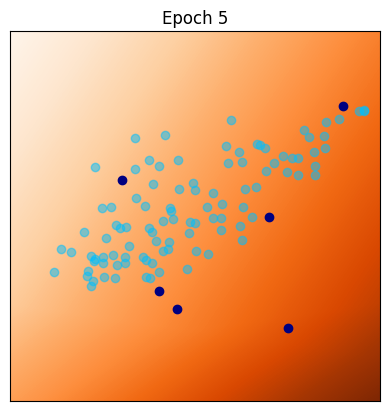

[6/100] 	Loss_D: 7.8256	Loss_G: -0.0978	Lip(D)=0.1162
[7/100] 	Loss_D: 7.6926	Loss_G: -0.1011	Lip(D)=0.1237
[8/100] 	Loss_D: 7.5564	Loss_G: -0.1076	Lip(D)=0.1315
[9/100] 	Loss_D: 7.4126	Loss_G: -0.1126	Lip(D)=0.1463
[10/100] 	Loss_D: 7.2681	Loss_G: -0.1198	Lip(D)=0.1483


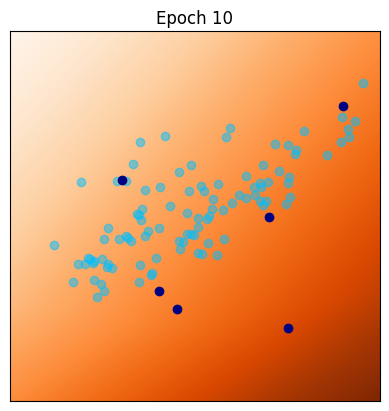

[11/100] 	Loss_D: 7.1158	Loss_G: -0.1229	Lip(D)=0.1573
[12/100] 	Loss_D: 6.9553	Loss_G: -0.1321	Lip(D)=0.1666
[13/100] 	Loss_D: 6.6941	Loss_G: -0.1377	Lip(D)=0.1763
[14/100] 	Loss_D: 6.5296	Loss_G: -0.1407	Lip(D)=0.1862
[15/100] 	Loss_D: 6.3716	Loss_G: -0.1455	Lip(D)=0.1965


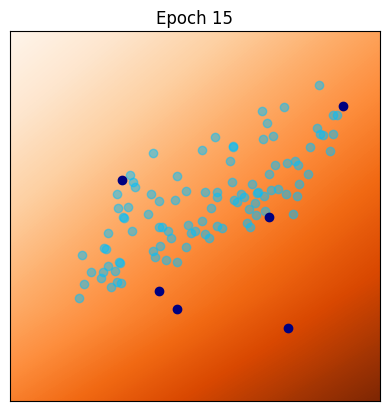

[16/100] 	Loss_D: 6.2978	Loss_G: -0.1503	Lip(D)=0.2071
[17/100] 	Loss_D: 6.1260	Loss_G: -0.1588	Lip(D)=0.2179
[18/100] 	Loss_D: 5.9497	Loss_G: -0.1638	Lip(D)=0.2348
[19/100] 	Loss_D: 5.7799	Loss_G: -0.1684	Lip(D)=0.2460
[20/100] 	Loss_D: 5.6051	Loss_G: -0.1729	Lip(D)=0.2629


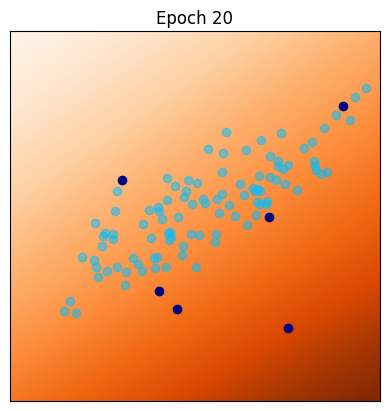

[21/100] 	Loss_D: 5.2710	Loss_G: -0.1805	Lip(D)=0.2793
[22/100] 	Loss_D: 5.0337	Loss_G: -0.1879	Lip(D)=0.3023
[23/100] 	Loss_D: 4.8589	Loss_G: -0.1978	Lip(D)=0.3030
[24/100] 	Loss_D: 4.4684	Loss_G: -0.2081	Lip(D)=0.3264
[25/100] 	Loss_D: 4.1519	Loss_G: -0.2150	Lip(D)=0.3591


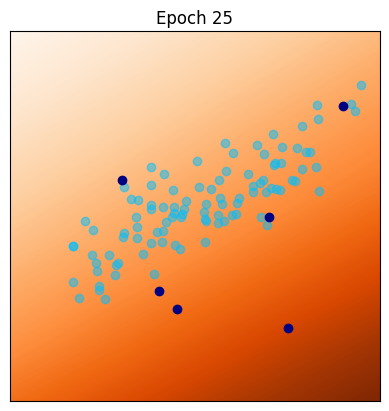

[26/100] 	Loss_D: 3.6295	Loss_G: -0.2266	Lip(D)=0.3648
[27/100] 	Loss_D: 3.7375	Loss_G: -0.2338	Lip(D)=0.4386
[28/100] 	Loss_D: 3.2041	Loss_G: -0.2441	Lip(D)=0.4276
[29/100] 	Loss_D: 2.8776	Loss_G: -0.2565	Lip(D)=0.4403
[30/100] 	Loss_D: 2.6229	Loss_G: -0.2646	Lip(D)=0.4770


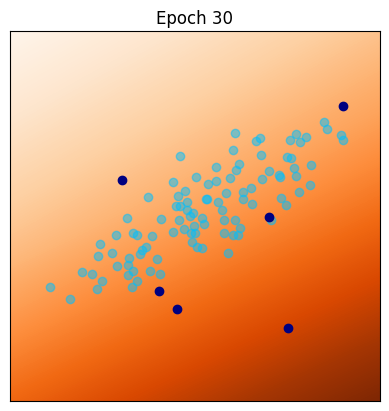

[31/100] 	Loss_D: 2.4523	Loss_G: -0.2720	Lip(D)=0.4634
[32/100] 	Loss_D: 1.9080	Loss_G: -0.2778	Lip(D)=0.5363
[33/100] 	Loss_D: 1.7933	Loss_G: -0.2872	Lip(D)=0.5593
[34/100] 	Loss_D: 1.9866	Loss_G: -0.2982	Lip(D)=0.6028
[35/100] 	Loss_D: 1.4062	Loss_G: -0.3084	Lip(D)=0.6027


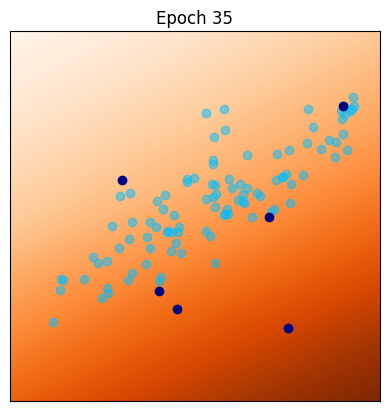

[36/100] 	Loss_D: 1.4892	Loss_G: -0.3152	Lip(D)=0.5889
[37/100] 	Loss_D: 1.4898	Loss_G: -0.3245	Lip(D)=0.6809
[38/100] 	Loss_D: 0.7580	Loss_G: -0.3254	Lip(D)=0.6605
[39/100] 	Loss_D: 1.0408	Loss_G: -0.3319	Lip(D)=0.6804
[40/100] 	Loss_D: 1.1629	Loss_G: -0.3371	Lip(D)=0.7502


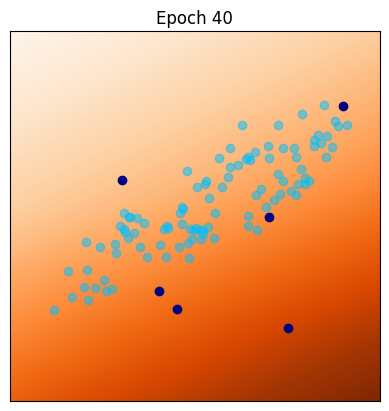

[41/100] 	Loss_D: 1.0548	Loss_G: -0.3446	Lip(D)=0.7487
[42/100] 	Loss_D: 0.7160	Loss_G: -0.3475	Lip(D)=0.7927
[43/100] 	Loss_D: 0.5652	Loss_G: -0.3444	Lip(D)=0.7732
[44/100] 	Loss_D: 0.3368	Loss_G: -0.3543	Lip(D)=0.8072
[45/100] 	Loss_D: 1.0816	Loss_G: -0.3681	Lip(D)=0.7446


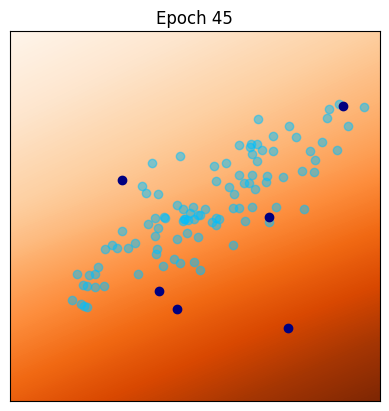

[46/100] 	Loss_D: 0.3810	Loss_G: -0.3555	Lip(D)=0.7676
[47/100] 	Loss_D: 0.6560	Loss_G: -0.3648	Lip(D)=0.7739
[48/100] 	Loss_D: 0.5287	Loss_G: -0.3651	Lip(D)=0.7926
[49/100] 	Loss_D: 0.5720	Loss_G: -0.3674	Lip(D)=0.8037
[50/100] 	Loss_D: 0.2543	Loss_G: -0.3721	Lip(D)=0.8147


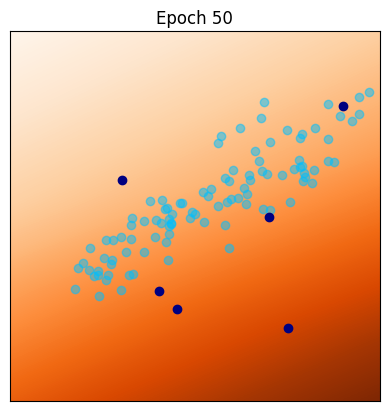

[51/100] 	Loss_D: 0.4992	Loss_G: -0.3780	Lip(D)=0.8850
[52/100] 	Loss_D: 0.2067	Loss_G: -0.3927	Lip(D)=0.8951
[53/100] 	Loss_D: 0.2660	Loss_G: -0.3738	Lip(D)=0.9626
[54/100] 	Loss_D: 0.3509	Loss_G: -0.3925	Lip(D)=0.7282
[55/100] 	Loss_D: 0.1682	Loss_G: -0.3931	Lip(D)=0.7342


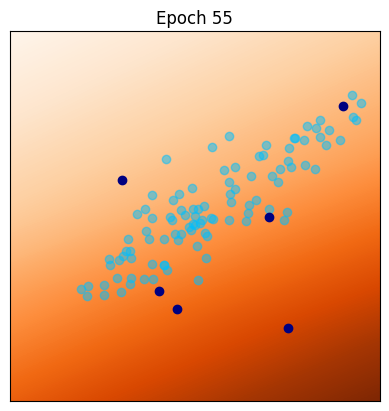

[56/100] 	Loss_D: 0.4204	Loss_G: -0.3983	Lip(D)=0.9482
[57/100] 	Loss_D: -0.0167	Loss_G: -0.3948	Lip(D)=1.0005
[58/100] 	Loss_D: 0.0523	Loss_G: -0.3783	Lip(D)=1.0068
[59/100] 	Loss_D: 0.3631	Loss_G: -0.4049	Lip(D)=0.9241
[60/100] 	Loss_D: 0.3577	Loss_G: -0.3769	Lip(D)=0.8892


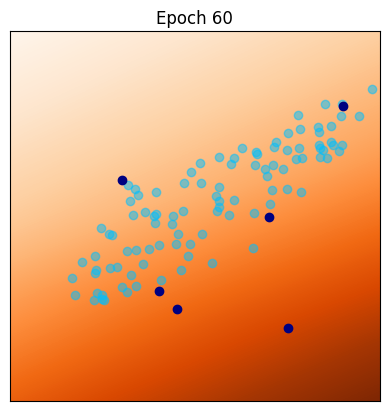

[61/100] 	Loss_D: 0.3435	Loss_G: -0.3875	Lip(D)=0.8945
[62/100] 	Loss_D: 0.3408	Loss_G: -0.4064	Lip(D)=0.8984
[63/100] 	Loss_D: 0.5988	Loss_G: -0.4114	Lip(D)=0.9048
[64/100] 	Loss_D: 0.1224	Loss_G: -0.4120	Lip(D)=0.9000
[65/100] 	Loss_D: 0.1681	Loss_G: -0.4019	Lip(D)=0.8793


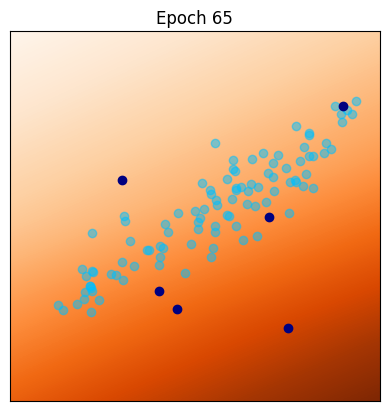

[66/100] 	Loss_D: 0.3146	Loss_G: -0.4039	Lip(D)=0.9802
[67/100] 	Loss_D: 0.2924	Loss_G: -0.4124	Lip(D)=0.9191
[68/100] 	Loss_D: 0.3379	Loss_G: -0.4118	Lip(D)=0.9849
[69/100] 	Loss_D: 0.3345	Loss_G: -0.4195	Lip(D)=0.9897
[70/100] 	Loss_D: 0.1064	Loss_G: -0.4231	Lip(D)=0.8779


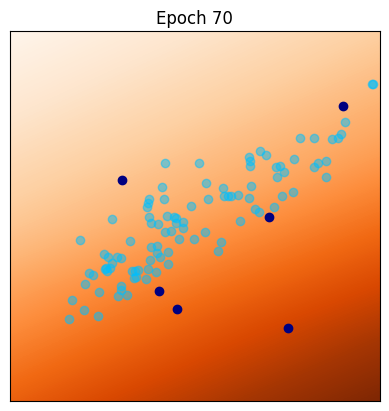

[71/100] 	Loss_D: 0.1069	Loss_G: -0.4127	Lip(D)=0.8320
[72/100] 	Loss_D: 0.2806	Loss_G: -0.4345	Lip(D)=0.9788
[73/100] 	Loss_D: 0.1128	Loss_G: -0.4293	Lip(D)=0.9028
[74/100] 	Loss_D: 0.0976	Loss_G: -0.4392	Lip(D)=0.9026
[75/100] 	Loss_D: 0.2622	Loss_G: -0.4277	Lip(D)=0.9997


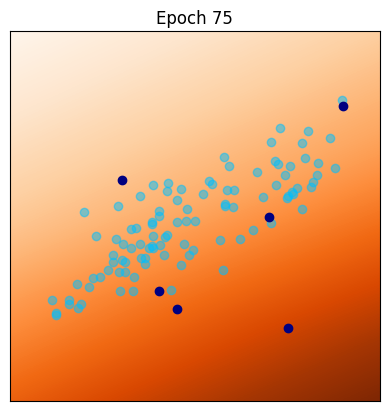

[76/100] 	Loss_D: 0.2663	Loss_G: -0.4228	Lip(D)=1.0014
[77/100] 	Loss_D: 0.2573	Loss_G: -0.4380	Lip(D)=0.9660
[78/100] 	Loss_D: 0.2782	Loss_G: -0.4416	Lip(D)=1.0647
[79/100] 	Loss_D: 0.0998	Loss_G: -0.4378	Lip(D)=0.9212
[80/100] 	Loss_D: 0.3860	Loss_G: -0.4323	Lip(D)=1.0060


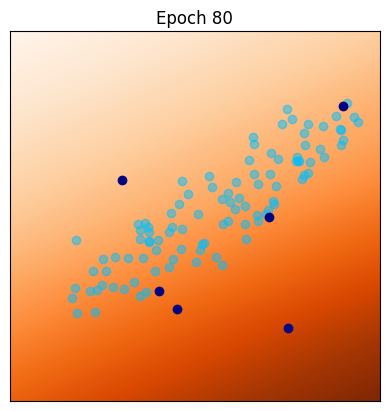

[81/100] 	Loss_D: 0.2247	Loss_G: -0.4446	Lip(D)=0.8795
[82/100] 	Loss_D: 0.2359	Loss_G: -0.4355	Lip(D)=0.9157
[83/100] 	Loss_D: -0.0325	Loss_G: -0.4567	Lip(D)=0.8903
[84/100] 	Loss_D: 0.3568	Loss_G: -0.4564	Lip(D)=0.8838
[85/100] 	Loss_D: 0.2101	Loss_G: -0.4443	Lip(D)=0.8326


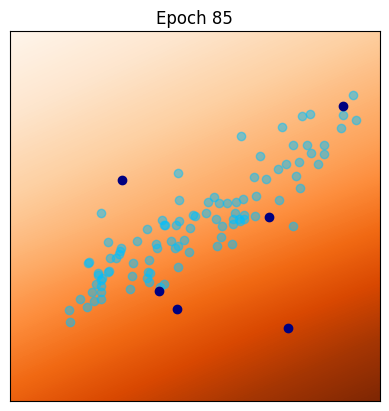

[86/100] 	Loss_D: 0.2202	Loss_G: -0.4520	Lip(D)=0.9553
[87/100] 	Loss_D: 0.3412	Loss_G: -0.4533	Lip(D)=0.9591
[88/100] 	Loss_D: 0.2126	Loss_G: -0.4611	Lip(D)=1.0809
[89/100] 	Loss_D: 0.0815	Loss_G: -0.4613	Lip(D)=1.0651
[90/100] 	Loss_D: 0.0886	Loss_G: -0.4630	Lip(D)=0.9426


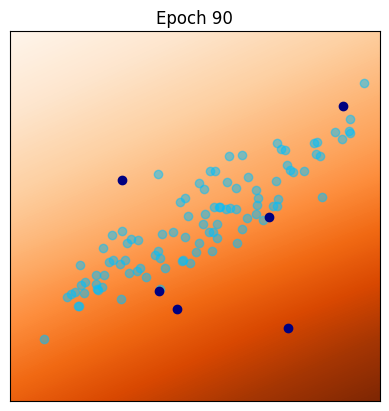

[91/100] 	Loss_D: 0.2113	Loss_G: -0.4665	Lip(D)=1.0162
[92/100] 	Loss_D: 0.0769	Loss_G: -0.4608	Lip(D)=0.9595
[93/100] 	Loss_D: 0.1891	Loss_G: -0.4644	Lip(D)=0.9599
[94/100] 	Loss_D: 0.0790	Loss_G: -0.4597	Lip(D)=1.0178
[95/100] 	Loss_D: -0.0255	Loss_G: -0.4608	Lip(D)=1.0187


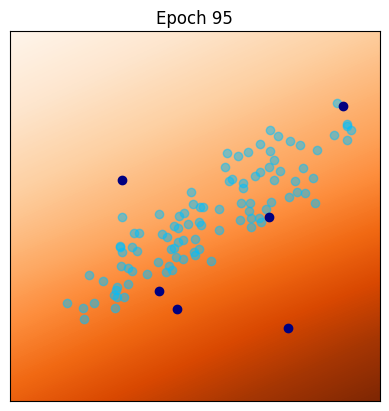

[96/100] 	Loss_D: 0.0748	Loss_G: -0.4581	Lip(D)=0.9606
[97/100] 	Loss_D: 0.0754	Loss_G: -0.4663	Lip(D)=0.9845
[98/100] 	Loss_D: 0.2009	Loss_G: -0.4691	Lip(D)=0.9623
[99/100] 	Loss_D: 0.0701	Loss_G: -0.4734	Lip(D)=0.9649


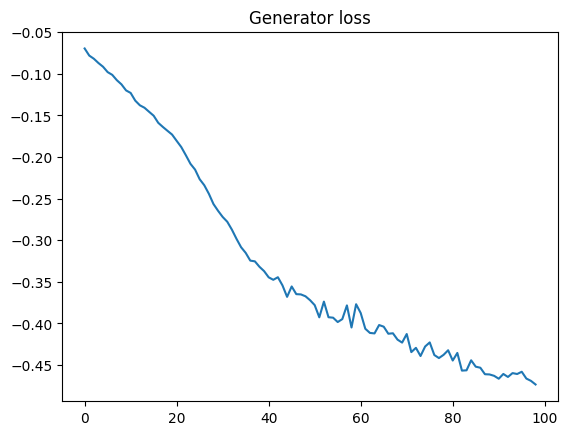

Experiment 2: {'lr_g': 0.0002, 'lr_d': 0.0002, 'niterD': 1, 'niterG': 1, 'gpw': 10, 'x': tensor([[1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 0.9999],
        [1.0000, 0.9998],
        [0.9999, 0.9998],
        [1.0000, 0.9999],
        [1.0000, 0.9998],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 0.9999],
        [0.9999, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 0.9997],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9998, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
 

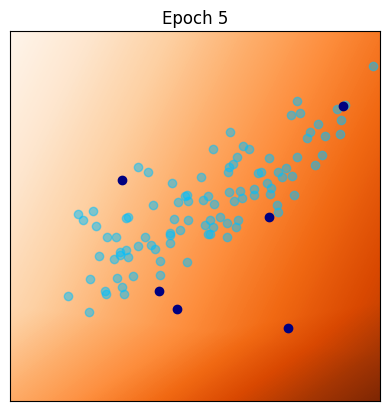

[6/100] 	Loss_D: 8.4830	Loss_G: -0.0683	Lip(D)=0.0791
[7/100] 	Loss_D: 8.4739	Loss_G: -0.0690	Lip(D)=0.0797
[8/100] 	Loss_D: 8.3314	Loss_G: -0.0696	Lip(D)=0.0804
[9/100] 	Loss_D: 8.4472	Loss_G: -0.0686	Lip(D)=0.0810
[10/100] 	Loss_D: 8.4379	Loss_G: -0.0698	Lip(D)=0.0817


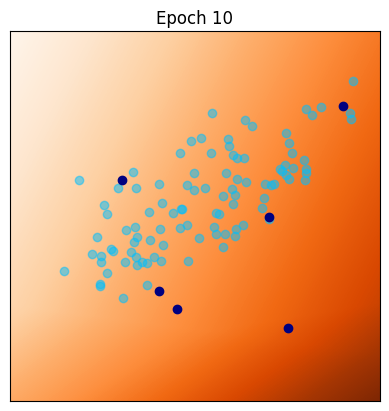

[11/100] 	Loss_D: 8.4253	Loss_G: -0.0705	Lip(D)=0.0823
[12/100] 	Loss_D: 8.4125	Loss_G: -0.0715	Lip(D)=0.0830
[13/100] 	Loss_D: 8.4004	Loss_G: -0.0713	Lip(D)=0.0836
[14/100] 	Loss_D: 8.3899	Loss_G: -0.0727	Lip(D)=0.0843
[15/100] 	Loss_D: 8.3793	Loss_G: -0.0767	Lip(D)=0.0849


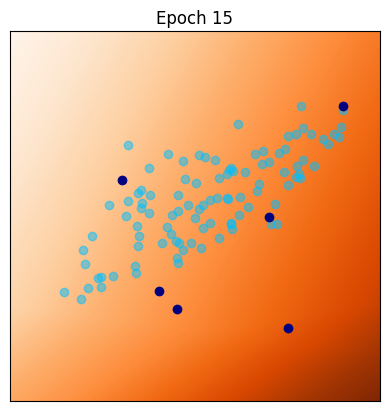

[16/100] 	Loss_D: 8.3659	Loss_G: -0.0729	Lip(D)=0.0856
[17/100] 	Loss_D: 8.3529	Loss_G: -0.0729	Lip(D)=0.0863
[18/100] 	Loss_D: 8.3403	Loss_G: -0.0771	Lip(D)=0.0869
[19/100] 	Loss_D: 8.3282	Loss_G: -0.0762	Lip(D)=0.0876
[20/100] 	Loss_D: 8.3188	Loss_G: -0.0788	Lip(D)=0.0953


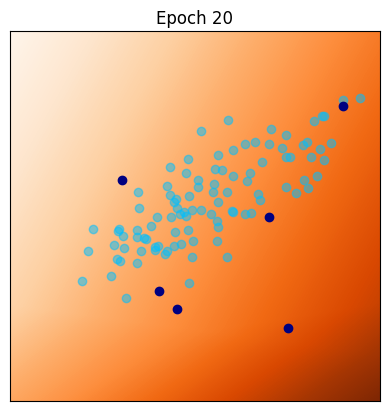

[21/100] 	Loss_D: 8.3023	Loss_G: -0.0765	Lip(D)=0.0889
[22/100] 	Loss_D: 8.2910	Loss_G: -0.0798	Lip(D)=0.0896
[23/100] 	Loss_D: 8.2820	Loss_G: -0.0779	Lip(D)=0.0902
[24/100] 	Loss_D: 8.2687	Loss_G: -0.0795	Lip(D)=0.0909
[25/100] 	Loss_D: 8.2558	Loss_G: -0.0791	Lip(D)=0.0986


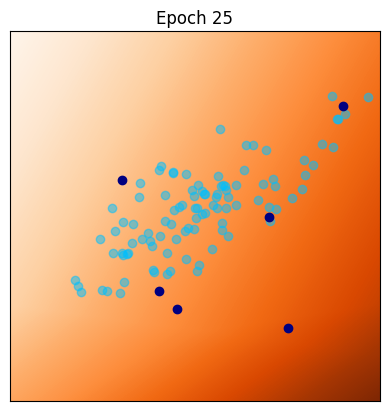

[26/100] 	Loss_D: 8.2443	Loss_G: -0.0819	Lip(D)=0.0923
[27/100] 	Loss_D: 8.2312	Loss_G: -0.0814	Lip(D)=0.0929
[28/100] 	Loss_D: 8.2196	Loss_G: -0.0827	Lip(D)=0.0936
[29/100] 	Loss_D: 8.2056	Loss_G: -0.0841	Lip(D)=0.0943
[30/100] 	Loss_D: 8.1959	Loss_G: -0.0830	Lip(D)=0.0950


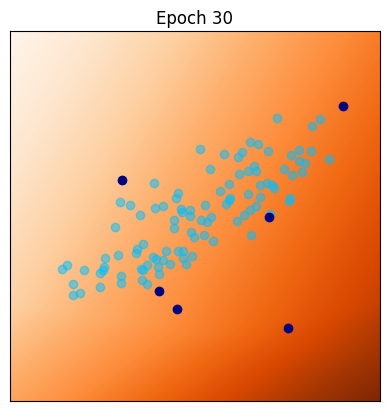

[31/100] 	Loss_D: 8.1825	Loss_G: -0.0849	Lip(D)=0.0956
[32/100] 	Loss_D: 8.1712	Loss_G: -0.0854	Lip(D)=0.0963
[33/100] 	Loss_D: 8.1577	Loss_G: -0.0854	Lip(D)=0.0970
[34/100] 	Loss_D: 8.1424	Loss_G: -0.0856	Lip(D)=0.0977
[35/100] 	Loss_D: 8.1327	Loss_G: -0.0855	Lip(D)=0.0984


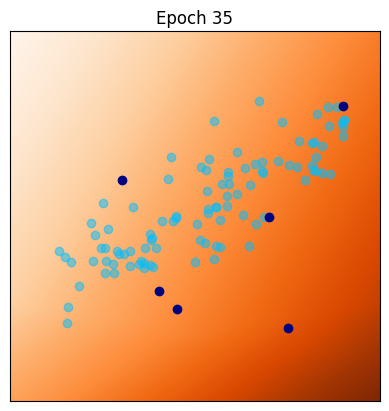

[36/100] 	Loss_D: 8.1183	Loss_G: -0.0870	Lip(D)=0.0991
[37/100] 	Loss_D: 8.1103	Loss_G: -0.0890	Lip(D)=0.0998
[38/100] 	Loss_D: 8.0943	Loss_G: -0.0903	Lip(D)=0.1005
[39/100] 	Loss_D: 8.0831	Loss_G: -0.0873	Lip(D)=0.1012
[40/100] 	Loss_D: 8.0690	Loss_G: -0.0915	Lip(D)=0.1019


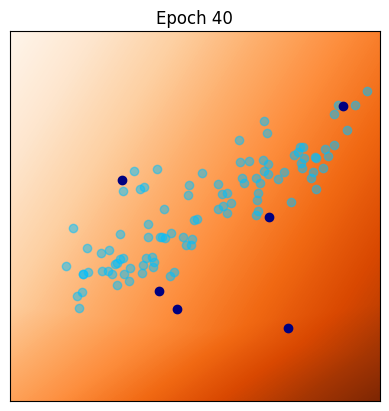

[41/100] 	Loss_D: 8.0590	Loss_G: -0.0935	Lip(D)=0.1026
[42/100] 	Loss_D: 7.9245	Loss_G: -0.0909	Lip(D)=0.1033
[43/100] 	Loss_D: 8.0336	Loss_G: -0.0928	Lip(D)=0.1040
[44/100] 	Loss_D: 8.0229	Loss_G: -0.0957	Lip(D)=0.1047
[45/100] 	Loss_D: 8.0088	Loss_G: -0.0933	Lip(D)=0.1123


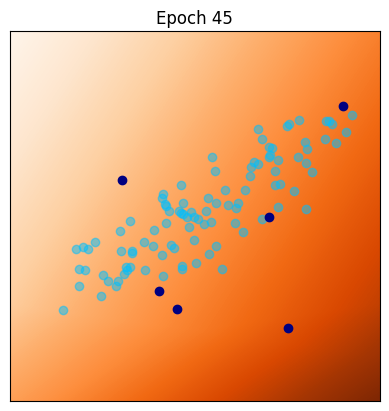

[46/100] 	Loss_D: 7.9946	Loss_G: -0.0926	Lip(D)=0.1130
[47/100] 	Loss_D: 7.9852	Loss_G: -0.0963	Lip(D)=0.1068
[48/100] 	Loss_D: 7.9679	Loss_G: -0.0964	Lip(D)=0.1075
[49/100] 	Loss_D: 7.8384	Loss_G: -0.0978	Lip(D)=0.1082
[50/100] 	Loss_D: 7.9452	Loss_G: -0.0949	Lip(D)=0.1089


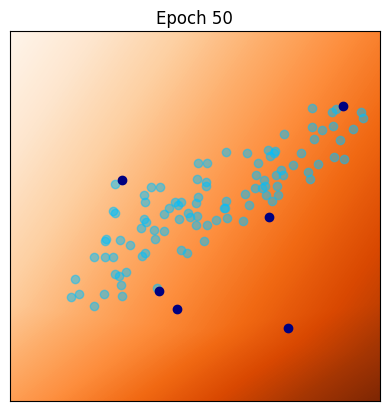

[51/100] 	Loss_D: 7.9311	Loss_G: -0.0993	Lip(D)=0.1096
[52/100] 	Loss_D: 7.9187	Loss_G: -0.0965	Lip(D)=0.1104
[53/100] 	Loss_D: 7.7870	Loss_G: -0.1029	Lip(D)=0.1111
[54/100] 	Loss_D: 7.7744	Loss_G: -0.0995	Lip(D)=0.1118
[55/100] 	Loss_D: 7.8826	Loss_G: -0.0990	Lip(D)=0.1125


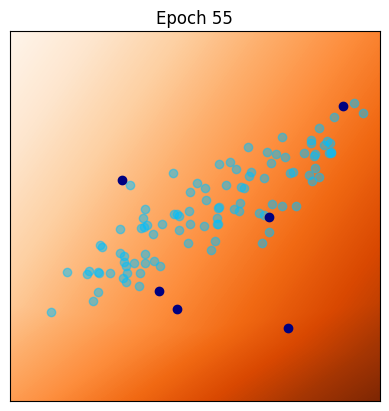

[56/100] 	Loss_D: 7.8685	Loss_G: -0.1020	Lip(D)=0.1133
[57/100] 	Loss_D: 7.8533	Loss_G: -0.0995	Lip(D)=0.1140
[58/100] 	Loss_D: 7.8433	Loss_G: -0.1036	Lip(D)=0.1147
[59/100] 	Loss_D: 7.8282	Loss_G: -0.1012	Lip(D)=0.1155
[60/100] 	Loss_D: 7.8149	Loss_G: -0.1048	Lip(D)=0.1162


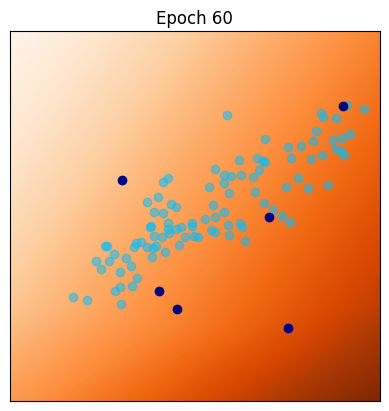

[61/100] 	Loss_D: 7.8028	Loss_G: -0.1045	Lip(D)=0.1170
[62/100] 	Loss_D: 7.7906	Loss_G: -0.1054	Lip(D)=0.1177
[63/100] 	Loss_D: 7.7764	Loss_G: -0.1040	Lip(D)=0.1185
[64/100] 	Loss_D: 7.7647	Loss_G: -0.1079	Lip(D)=0.1192
[65/100] 	Loss_D: 7.7501	Loss_G: -0.1081	Lip(D)=0.1268


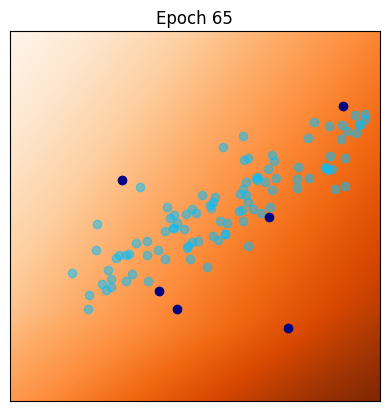

[66/100] 	Loss_D: 7.7347	Loss_G: -0.1037	Lip(D)=0.1275
[67/100] 	Loss_D: 7.7215	Loss_G: -0.1063	Lip(D)=0.1283
[68/100] 	Loss_D: 7.5951	Loss_G: -0.1090	Lip(D)=0.1223
[69/100] 	Loss_D: 7.6974	Loss_G: -0.1067	Lip(D)=0.1230
[70/100] 	Loss_D: 7.6834	Loss_G: -0.1074	Lip(D)=0.1306


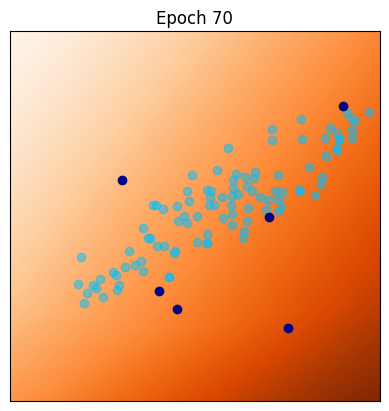

[71/100] 	Loss_D: 7.6695	Loss_G: -0.1116	Lip(D)=0.1246
[72/100] 	Loss_D: 7.6551	Loss_G: -0.1145	Lip(D)=0.1254
[73/100] 	Loss_D: 7.5277	Loss_G: -0.1104	Lip(D)=0.1261
[74/100] 	Loss_D: 7.6274	Loss_G: -0.1129	Lip(D)=0.1336
[75/100] 	Loss_D: 7.6130	Loss_G: -0.1139	Lip(D)=0.1277


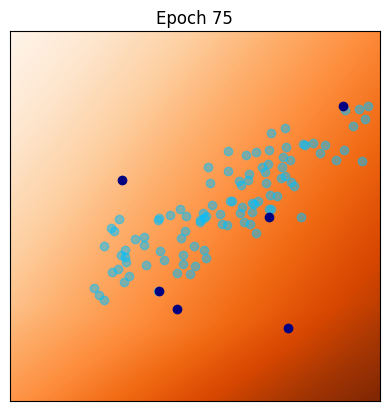

[76/100] 	Loss_D: 7.6008	Loss_G: -0.1143	Lip(D)=0.1285
[77/100] 	Loss_D: 7.5874	Loss_G: -0.1169	Lip(D)=0.1293
[78/100] 	Loss_D: 7.4563	Loss_G: -0.1143	Lip(D)=0.1301
[79/100] 	Loss_D: 7.5593	Loss_G: -0.1167	Lip(D)=0.1309
[80/100] 	Loss_D: 7.5470	Loss_G: -0.1144	Lip(D)=0.1317


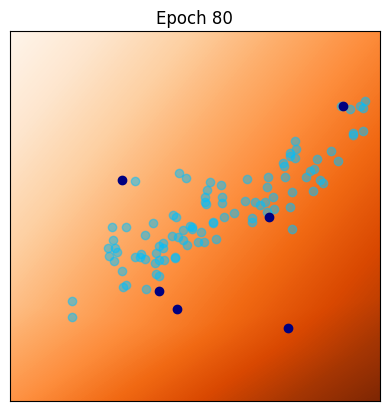

[81/100] 	Loss_D: 7.4192	Loss_G: -0.1161	Lip(D)=0.1392
[82/100] 	Loss_D: 7.5218	Loss_G: -0.1162	Lip(D)=0.1333
[83/100] 	Loss_D: 7.5057	Loss_G: -0.1188	Lip(D)=0.1341
[84/100] 	Loss_D: 7.4908	Loss_G: -0.1205	Lip(D)=0.1350
[85/100] 	Loss_D: 7.4764	Loss_G: -0.1197	Lip(D)=0.1358


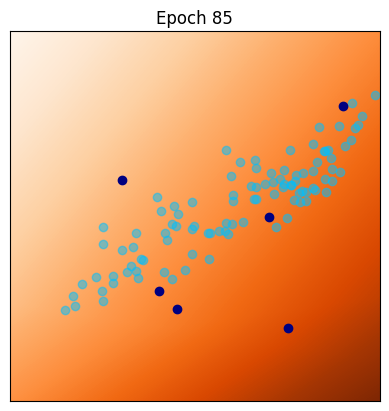

[86/100] 	Loss_D: 7.4619	Loss_G: -0.1200	Lip(D)=0.1366
[87/100] 	Loss_D: 7.4456	Loss_G: -0.1230	Lip(D)=0.1441
[88/100] 	Loss_D: 7.4306	Loss_G: -0.1214	Lip(D)=0.1450
[89/100] 	Loss_D: 7.4176	Loss_G: -0.1243	Lip(D)=0.1458
[90/100] 	Loss_D: 7.4058	Loss_G: -0.1237	Lip(D)=0.1400


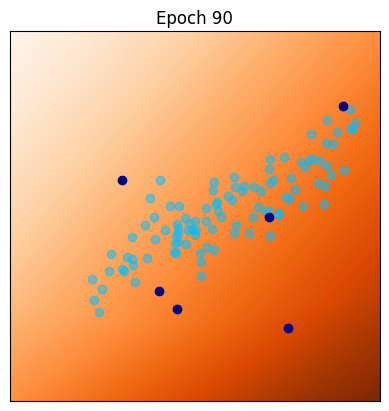

[91/100] 	Loss_D: 7.3881	Loss_G: -0.1223	Lip(D)=0.1408
[92/100] 	Loss_D: 7.2639	Loss_G: -0.1235	Lip(D)=0.1483
[93/100] 	Loss_D: 7.3623	Loss_G: -0.1240	Lip(D)=0.1425
[94/100] 	Loss_D: 7.3441	Loss_G: -0.1267	Lip(D)=0.1500
[95/100] 	Loss_D: 7.3313	Loss_G: -0.1278	Lip(D)=0.1443


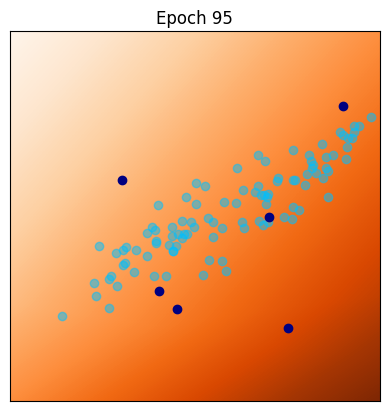

[96/100] 	Loss_D: 7.3182	Loss_G: -0.1257	Lip(D)=0.1451
[97/100] 	Loss_D: 7.1910	Loss_G: -0.1255	Lip(D)=0.1460
[98/100] 	Loss_D: 7.2856	Loss_G: -0.1285	Lip(D)=0.1469
[99/100] 	Loss_D: 7.2716	Loss_G: -0.1297	Lip(D)=0.1478


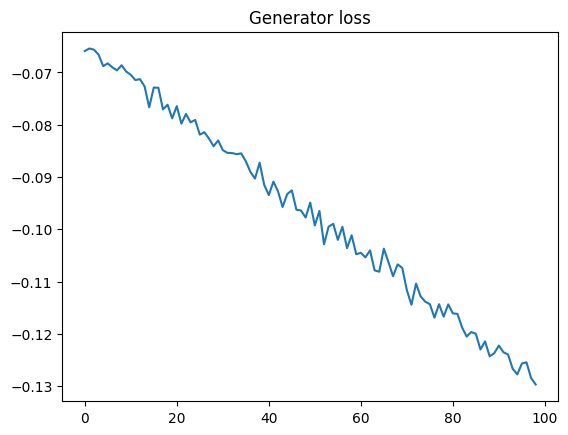

Experiment 3: {'lr_g': 0.0001, 'lr_d': 0.0001, 'niterD': 5, 'niterG': 1, 'gpw': 1, 'x': tensor([[1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 0.9999],
        [1.0000, 0.9998],
        [0.9999, 0.9998],
        [1.0000, 0.9999],
        [1.0000, 0.9998],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 0.9999],
        [0.9999, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 0.9997],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9998, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
  

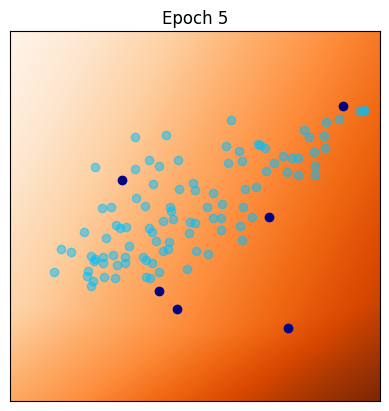

[6/100] 	Loss_D: 0.8293	Loss_G: -0.0733	Lip(D)=0.0849
[7/100] 	Loss_D: 0.8259	Loss_G: -0.0728	Lip(D)=0.0866
[8/100] 	Loss_D: 0.8234	Loss_G: -0.0751	Lip(D)=0.0882
[9/100] 	Loss_D: 0.8181	Loss_G: -0.0764	Lip(D)=0.0970
[10/100] 	Loss_D: 0.8175	Loss_G: -0.0802	Lip(D)=0.0916


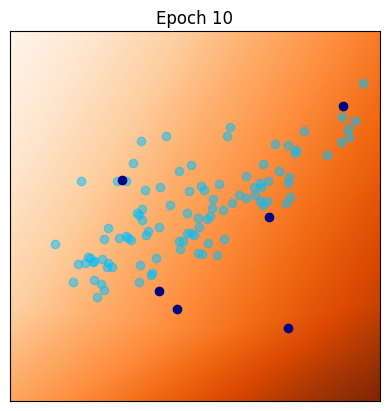

[11/100] 	Loss_D: 0.8142	Loss_G: -0.0797	Lip(D)=0.0932
[12/100] 	Loss_D: 0.8080	Loss_G: -0.0839	Lip(D)=0.0949
[13/100] 	Loss_D: 0.7938	Loss_G: -0.0852	Lip(D)=0.0966
[14/100] 	Loss_D: 0.7996	Loss_G: -0.0837	Lip(D)=0.0984
[15/100] 	Loss_D: 0.7896	Loss_G: -0.0867	Lip(D)=0.1001


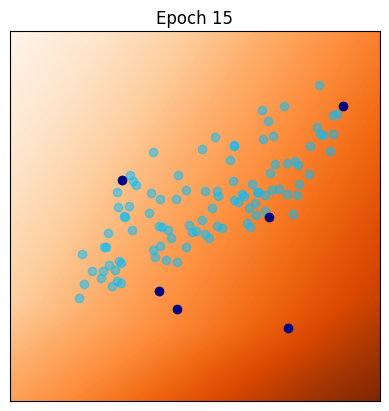

[16/100] 	Loss_D: 0.7967	Loss_G: -0.0857	Lip(D)=0.1018
[17/100] 	Loss_D: 0.7949	Loss_G: -0.0901	Lip(D)=0.1036
[18/100] 	Loss_D: 0.7890	Loss_G: -0.0895	Lip(D)=0.1054
[19/100] 	Loss_D: 0.7870	Loss_G: -0.0899	Lip(D)=0.1072
[20/100] 	Loss_D: 0.7838	Loss_G: -0.0908	Lip(D)=0.1159


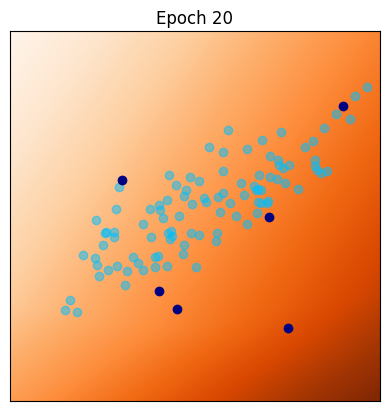

[21/100] 	Loss_D: 0.7801	Loss_G: -0.0914	Lip(D)=0.1177
[22/100] 	Loss_D: 0.7635	Loss_G: -0.0930	Lip(D)=0.1195
[23/100] 	Loss_D: 0.7731	Loss_G: -0.0942	Lip(D)=0.1145
[24/100] 	Loss_D: 0.7685	Loss_G: -0.0972	Lip(D)=0.1164
[25/100] 	Loss_D: 0.7667	Loss_G: -0.0978	Lip(D)=0.1252


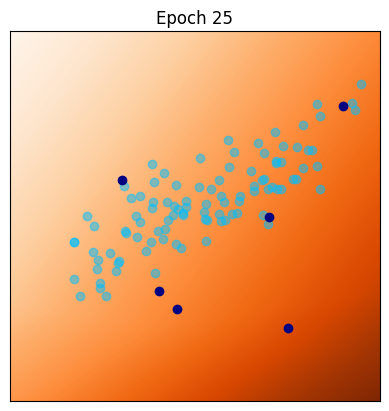

[26/100] 	Loss_D: 0.7603	Loss_G: -0.0983	Lip(D)=0.1203
[27/100] 	Loss_D: 0.7562	Loss_G: -0.1002	Lip(D)=0.1291
[28/100] 	Loss_D: 0.7427	Loss_G: -0.1022	Lip(D)=0.1242
[29/100] 	Loss_D: 0.7496	Loss_G: -0.1009	Lip(D)=0.1262
[30/100] 	Loss_D: 0.7464	Loss_G: -0.1050	Lip(D)=0.1283


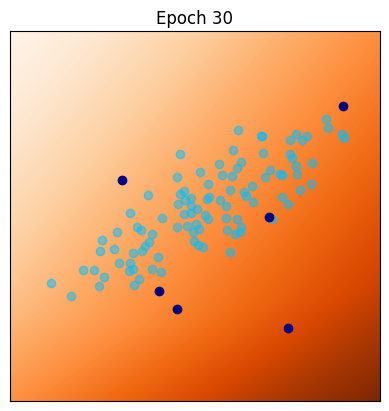

[31/100] 	Loss_D: 0.7438	Loss_G: -0.1036	Lip(D)=0.1303
[32/100] 	Loss_D: 0.7399	Loss_G: -0.1059	Lip(D)=0.1324
[33/100] 	Loss_D: 0.7244	Loss_G: -0.1069	Lip(D)=0.1345
[34/100] 	Loss_D: 0.7306	Loss_G: -0.1092	Lip(D)=0.1366
[35/100] 	Loss_D: 0.7277	Loss_G: -0.1101	Lip(D)=0.1388


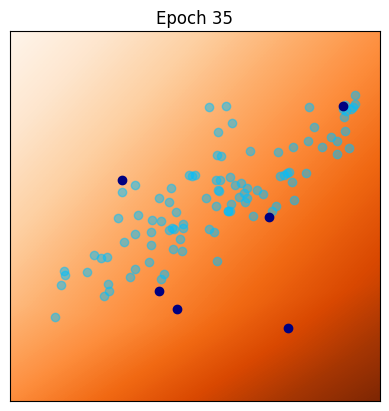

[36/100] 	Loss_D: 0.7235	Loss_G: -0.1110	Lip(D)=0.1410
[37/100] 	Loss_D: 0.7194	Loss_G: -0.1126	Lip(D)=0.1432
[38/100] 	Loss_D: 0.7142	Loss_G: -0.1143	Lip(D)=0.1454
[39/100] 	Loss_D: 0.7153	Loss_G: -0.1150	Lip(D)=0.1543
[40/100] 	Loss_D: 0.7073	Loss_G: -0.1179	Lip(D)=0.1499


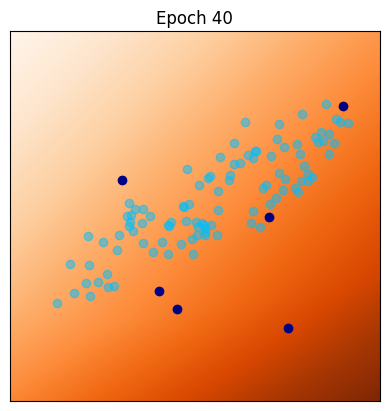

[41/100] 	Loss_D: 0.7030	Loss_G: -0.1153	Lip(D)=0.1522
[42/100] 	Loss_D: 0.6997	Loss_G: -0.1196	Lip(D)=0.1545
[43/100] 	Loss_D: 0.6940	Loss_G: -0.1203	Lip(D)=0.1568
[44/100] 	Loss_D: 0.6901	Loss_G: -0.1223	Lip(D)=0.1658
[45/100] 	Loss_D: 0.6894	Loss_G: -0.1220	Lip(D)=0.1616


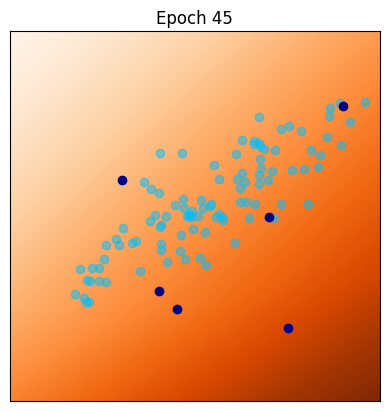

[46/100] 	Loss_D: 0.6812	Loss_G: -0.1239	Lip(D)=0.1639
[47/100] 	Loss_D: 0.6792	Loss_G: -0.1248	Lip(D)=0.1663
[48/100] 	Loss_D: 0.6760	Loss_G: -0.1237	Lip(D)=0.1687
[49/100] 	Loss_D: 0.6703	Loss_G: -0.1285	Lip(D)=0.1712
[50/100] 	Loss_D: 0.6554	Loss_G: -0.1279	Lip(D)=0.1736


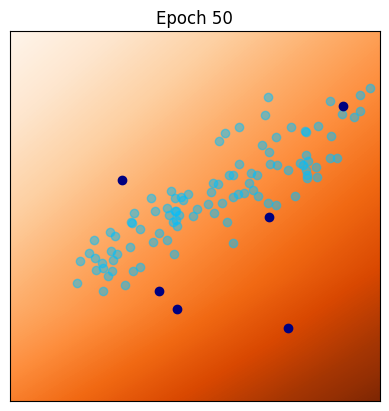

[51/100] 	Loss_D: 0.6404	Loss_G: -0.1307	Lip(D)=0.1760
[52/100] 	Loss_D: 0.6448	Loss_G: -0.1345	Lip(D)=0.1785
[53/100] 	Loss_D: 0.6495	Loss_G: -0.1337	Lip(D)=0.1810
[54/100] 	Loss_D: 0.6484	Loss_G: -0.1361	Lip(D)=0.1834
[55/100] 	Loss_D: 0.6351	Loss_G: -0.1382	Lip(D)=0.1859


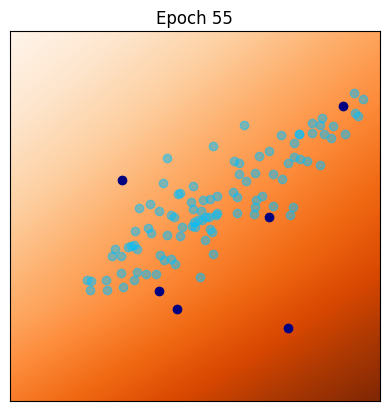

[56/100] 	Loss_D: 0.6307	Loss_G: -0.1373	Lip(D)=0.1948
[57/100] 	Loss_D: 0.6235	Loss_G: -0.1394	Lip(D)=0.1909
[58/100] 	Loss_D: 0.6300	Loss_G: -0.1385	Lip(D)=0.1934
[59/100] 	Loss_D: 0.6276	Loss_G: -0.1433	Lip(D)=0.2148
[60/100] 	Loss_D: 0.5929	Loss_G: -0.1391	Lip(D)=0.1985


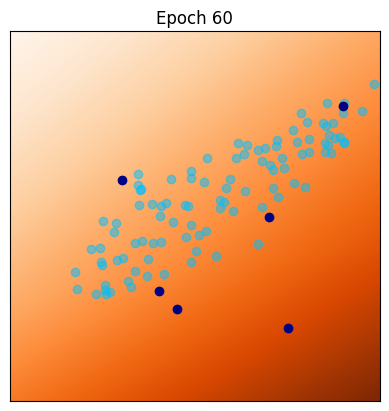

[61/100] 	Loss_D: 0.6085	Loss_G: -0.1443	Lip(D)=0.2135
[62/100] 	Loss_D: 0.6020	Loss_G: -0.1460	Lip(D)=0.2161
[63/100] 	Loss_D: 0.6098	Loss_G: -0.1477	Lip(D)=0.2248
[64/100] 	Loss_D: 0.5942	Loss_G: -0.1510	Lip(D)=0.2212
[65/100] 	Loss_D: 0.5823	Loss_G: -0.1486	Lip(D)=0.2299


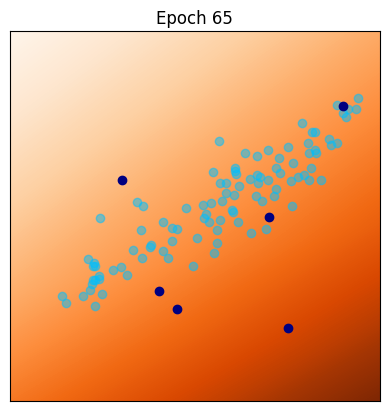

[66/100] 	Loss_D: 0.5791	Loss_G: -0.1512	Lip(D)=0.2201
[67/100] 	Loss_D: 0.5807	Loss_G: -0.1539	Lip(D)=0.2227
[68/100] 	Loss_D: 0.5766	Loss_G: -0.1540	Lip(D)=0.2375
[69/100] 	Loss_D: 0.5736	Loss_G: -0.1591	Lip(D)=0.2218
[70/100] 	Loss_D: 0.5591	Loss_G: -0.1591	Lip(D)=0.2245


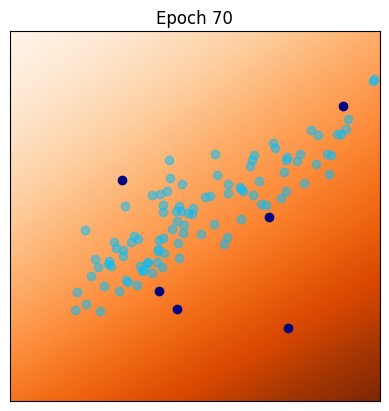

[71/100] 	Loss_D: 0.5467	Loss_G: -0.1597	Lip(D)=0.2392
[72/100] 	Loss_D: 0.5529	Loss_G: -0.1631	Lip(D)=0.2479
[73/100] 	Loss_D: 0.5575	Loss_G: -0.1641	Lip(D)=0.2445
[74/100] 	Loss_D: 0.5417	Loss_G: -0.1675	Lip(D)=0.2471
[75/100] 	Loss_D: 0.5288	Loss_G: -0.1667	Lip(D)=0.2498


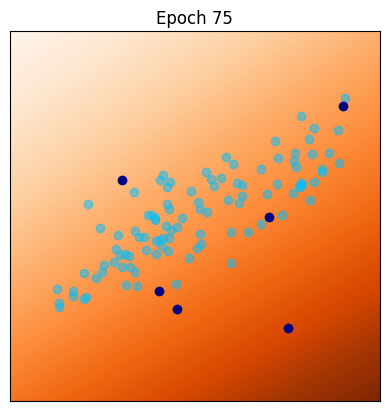

[76/100] 	Loss_D: 0.5359	Loss_G: -0.1678	Lip(D)=0.2584
[77/100] 	Loss_D: 0.5302	Loss_G: -0.1715	Lip(D)=0.2551
[78/100] 	Loss_D: 0.5157	Loss_G: -0.1741	Lip(D)=0.2577
[79/100] 	Loss_D: 0.5038	Loss_G: -0.1741	Lip(D)=0.2604
[80/100] 	Loss_D: 0.5236	Loss_G: -0.1737	Lip(D)=0.2690


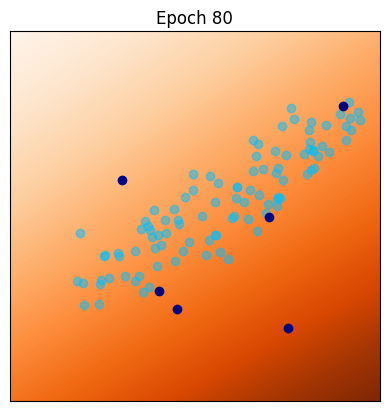

[81/100] 	Loss_D: 0.5030	Loss_G: -0.1768	Lip(D)=0.2658
[82/100] 	Loss_D: 0.5084	Loss_G: -0.1782	Lip(D)=0.2686
[83/100] 	Loss_D: 0.4970	Loss_G: -0.1854	Lip(D)=0.2713
[84/100] 	Loss_D: 0.4925	Loss_G: -0.1864	Lip(D)=0.2741
[85/100] 	Loss_D: 0.4941	Loss_G: -0.1859	Lip(D)=0.2769


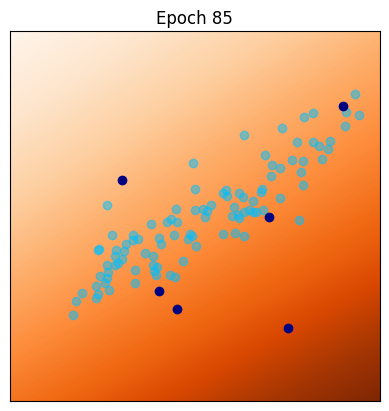

[86/100] 	Loss_D: 0.4933	Loss_G: -0.1896	Lip(D)=0.2854
[87/100] 	Loss_D: 0.4885	Loss_G: -0.1914	Lip(D)=0.2882
[88/100] 	Loss_D: 0.4680	Loss_G: -0.1965	Lip(D)=0.3136
[89/100] 	Loss_D: 0.4512	Loss_G: -0.1985	Lip(D)=0.2938
[90/100] 	Loss_D: 0.4602	Loss_G: -0.1992	Lip(D)=0.2909


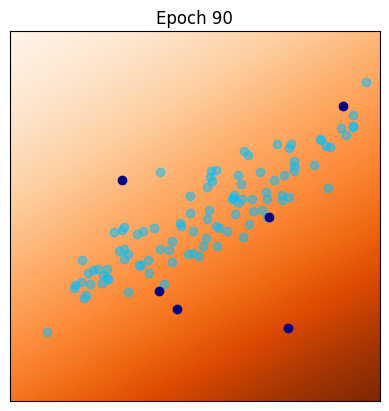

[91/100] 	Loss_D: 0.4576	Loss_G: -0.2016	Lip(D)=0.3108
[92/100] 	Loss_D: 0.4497	Loss_G: -0.2020	Lip(D)=0.3195
[93/100] 	Loss_D: 0.4375	Loss_G: -0.2066	Lip(D)=0.3224
[94/100] 	Loss_D: 0.4017	Loss_G: -0.2065	Lip(D)=0.3311
[95/100] 	Loss_D: 0.3918	Loss_G: -0.2079	Lip(D)=0.3461


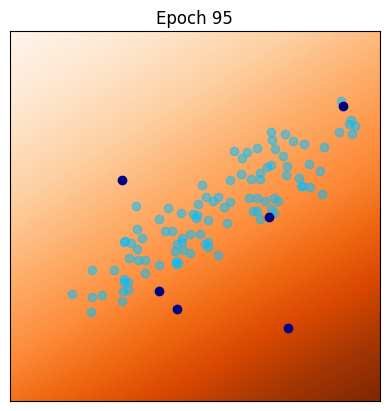

[96/100] 	Loss_D: 0.4145	Loss_G: -0.2120	Lip(D)=0.3437
[97/100] 	Loss_D: 0.3731	Loss_G: -0.2136	Lip(D)=0.3592
[98/100] 	Loss_D: 0.3738	Loss_G: -0.2173	Lip(D)=0.3501
[99/100] 	Loss_D: 0.3628	Loss_G: -0.2220	Lip(D)=0.3684


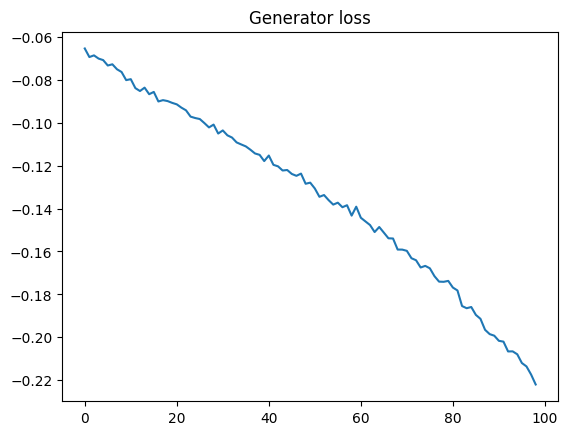

Experiment 4: {'lr_g': 0.0004, 'lr_d': 0.0004, 'niterD': 1, 'niterG': 1, 'gpw': 10, 'x': tensor([[1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 0.9999],
        [1.0000, 0.9998],
        [0.9999, 0.9998],
        [1.0000, 0.9999],
        [1.0000, 0.9998],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 0.9999],
        [0.9999, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 0.9997],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9998, 0.9999],
        [1.0000, 1.0000],
        [1.0000, 1.0000],
        [0.9999, 0.9999],
        [1.0000, 0.9999],
        [1.0000, 1.0000],
 

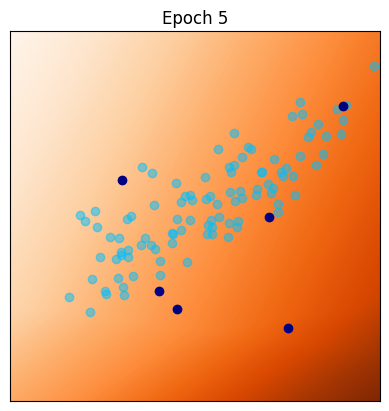

[6/100] 	Loss_D: 8.4239	Loss_G: -0.0721	Lip(D)=0.0830
[7/100] 	Loss_D: 8.4028	Loss_G: -0.0736	Lip(D)=0.0843
[8/100] 	Loss_D: 8.2499	Loss_G: -0.0749	Lip(D)=0.0856
[9/100] 	Loss_D: 8.3520	Loss_G: -0.0746	Lip(D)=0.0869
[10/100] 	Loss_D: 8.3306	Loss_G: -0.0767	Lip(D)=0.0882


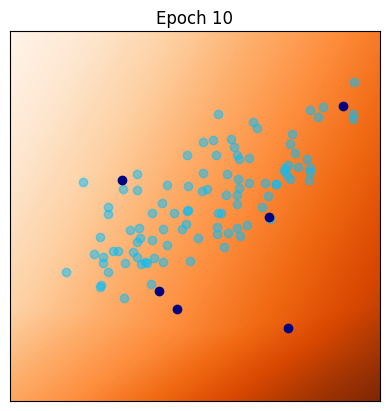

[11/100] 	Loss_D: 8.3056	Loss_G: -0.0780	Lip(D)=0.0895
[12/100] 	Loss_D: 8.2804	Loss_G: -0.0796	Lip(D)=0.0909
[13/100] 	Loss_D: 8.2560	Loss_G: -0.0801	Lip(D)=0.0922
[14/100] 	Loss_D: 8.2330	Loss_G: -0.0822	Lip(D)=0.0936
[15/100] 	Loss_D: 8.2101	Loss_G: -0.0870	Lip(D)=0.0949


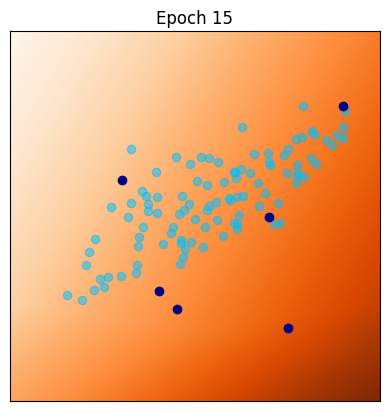

[16/100] 	Loss_D: 8.1839	Loss_G: -0.0835	Lip(D)=0.0963
[17/100] 	Loss_D: 8.1584	Loss_G: -0.0842	Lip(D)=0.0977
[18/100] 	Loss_D: 8.1331	Loss_G: -0.0893	Lip(D)=0.0990
[19/100] 	Loss_D: 8.1081	Loss_G: -0.0888	Lip(D)=0.1004
[20/100] 	Loss_D: 8.0861	Loss_G: -0.0923	Lip(D)=0.1087


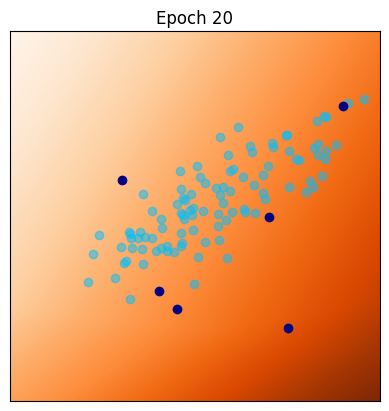

[21/100] 	Loss_D: 8.0565	Loss_G: -0.0904	Lip(D)=0.1032
[22/100] 	Loss_D: 8.0323	Loss_G: -0.0943	Lip(D)=0.1046
[23/100] 	Loss_D: 8.0105	Loss_G: -0.0932	Lip(D)=0.1060
[24/100] 	Loss_D: 7.9842	Loss_G: -0.0954	Lip(D)=0.1074
[25/100] 	Loss_D: 7.9579	Loss_G: -0.0957	Lip(D)=0.1157


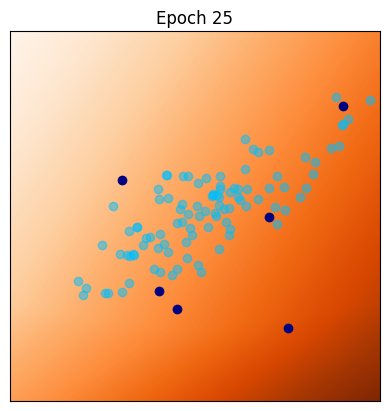

[26/100] 	Loss_D: 7.9332	Loss_G: -0.0989	Lip(D)=0.1103
[27/100] 	Loss_D: 7.9069	Loss_G: -0.0994	Lip(D)=0.1117
[28/100] 	Loss_D: 7.8820	Loss_G: -0.1011	Lip(D)=0.1132
[29/100] 	Loss_D: 7.8546	Loss_G: -0.1034	Lip(D)=0.1147
[30/100] 	Loss_D: 7.8315	Loss_G: -0.1027	Lip(D)=0.1161


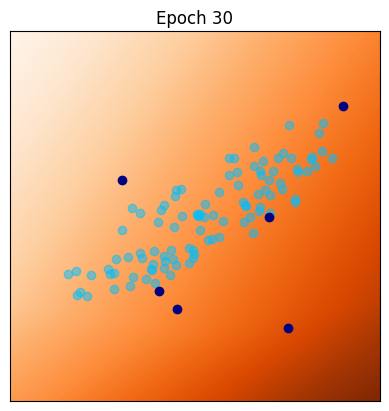

[31/100] 	Loss_D: 7.8039	Loss_G: -0.1051	Lip(D)=0.1244
[32/100] 	Loss_D: 7.7792	Loss_G: -0.1062	Lip(D)=0.1191
[33/100] 	Loss_D: 7.7515	Loss_G: -0.1070	Lip(D)=0.1206
[34/100] 	Loss_D: 7.6065	Loss_G: -0.1070	Lip(D)=0.1221
[35/100] 	Loss_D: 7.6987	Loss_G: -0.1080	Lip(D)=0.1236


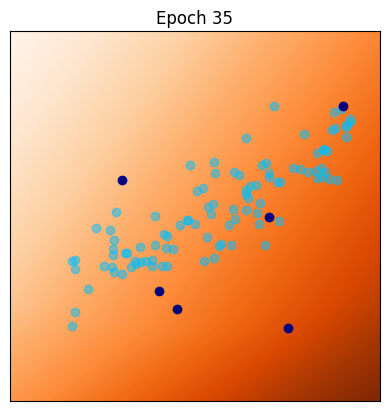

[36/100] 	Loss_D: 7.6701	Loss_G: -0.1105	Lip(D)=0.1252
[37/100] 	Loss_D: 7.6478	Loss_G: -0.1130	Lip(D)=0.1267
[38/100] 	Loss_D: 7.6169	Loss_G: -0.1152	Lip(D)=0.1283
[39/100] 	Loss_D: 7.5910	Loss_G: -0.1132	Lip(D)=0.1299
[40/100] 	Loss_D: 7.5617	Loss_G: -0.1177	Lip(D)=0.1315


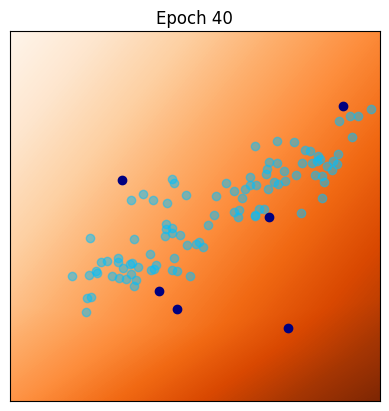

[41/100] 	Loss_D: 7.5375	Loss_G: -0.1207	Lip(D)=0.1397
[42/100] 	Loss_D: 7.3958	Loss_G: -0.1182	Lip(D)=0.1347
[43/100] 	Loss_D: 7.4814	Loss_G: -0.1206	Lip(D)=0.1363
[44/100] 	Loss_D: 7.4546	Loss_G: -0.1247	Lip(D)=0.1380
[45/100] 	Loss_D: 7.4250	Loss_G: -0.1228	Lip(D)=0.1462


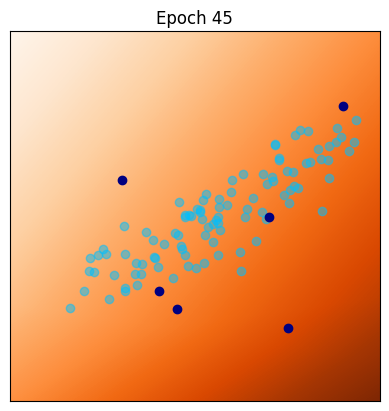

[46/100] 	Loss_D: 7.3943	Loss_G: -0.1221	Lip(D)=0.1479
[47/100] 	Loss_D: 7.3691	Loss_G: -0.1267	Lip(D)=0.1430
[48/100] 	Loss_D: 7.3351	Loss_G: -0.1276	Lip(D)=0.1447
[49/100] 	Loss_D: 7.1994	Loss_G: -0.1288	Lip(D)=0.1464
[50/100] 	Loss_D: 7.2792	Loss_G: -0.1281	Lip(D)=0.1482


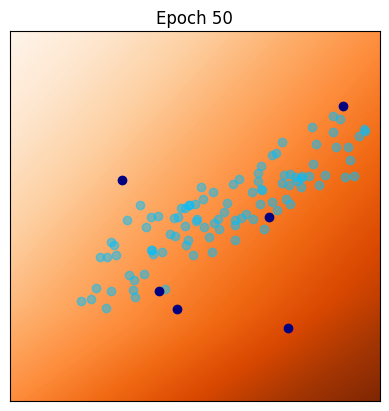

[51/100] 	Loss_D: 7.2492	Loss_G: -0.1323	Lip(D)=0.1499
[52/100] 	Loss_D: 7.1102	Loss_G: -0.1312	Lip(D)=0.1517
[53/100] 	Loss_D: 7.0803	Loss_G: -0.1374	Lip(D)=0.1535
[54/100] 	Loss_D: 7.0518	Loss_G: -0.1351	Lip(D)=0.1553
[55/100] 	Loss_D: 7.1322	Loss_G: -0.1347	Lip(D)=0.1571


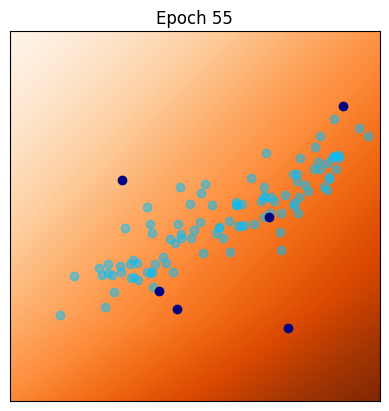

[56/100] 	Loss_D: 7.1001	Loss_G: -0.1387	Lip(D)=0.1654
[57/100] 	Loss_D: 7.0676	Loss_G: -0.1370	Lip(D)=0.1608
[58/100] 	Loss_D: 7.0392	Loss_G: -0.1412	Lip(D)=0.1626
[59/100] 	Loss_D: 7.0064	Loss_G: -0.1409	Lip(D)=0.1645
[60/100] 	Loss_D: 6.9753	Loss_G: -0.1450	Lip(D)=0.1664


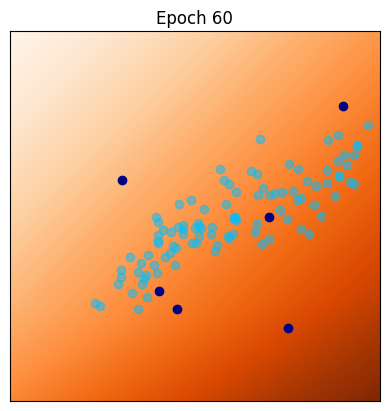

[61/100] 	Loss_D: 6.8393	Loss_G: -0.1457	Lip(D)=0.1747
[62/100] 	Loss_D: 6.9132	Loss_G: -0.1473	Lip(D)=0.1702
[63/100] 	Loss_D: 6.8807	Loss_G: -0.1456	Lip(D)=0.1785
[64/100] 	Loss_D: 6.8512	Loss_G: -0.1516	Lip(D)=0.1741
[65/100] 	Loss_D: 6.8165	Loss_G: -0.1533	Lip(D)=0.1824


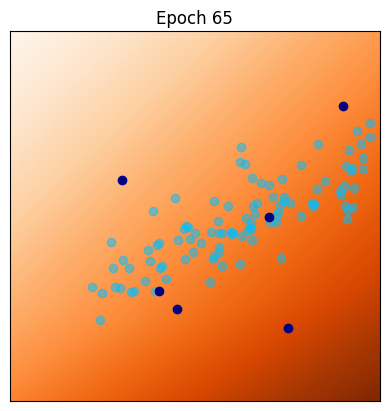

[66/100] 	Loss_D: 6.7829	Loss_G: -0.1503	Lip(D)=0.1844
[67/100] 	Loss_D: 6.7505	Loss_G: -0.1530	Lip(D)=0.1864
[68/100] 	Loss_D: 6.6202	Loss_G: -0.1568	Lip(D)=0.1820
[69/100] 	Loss_D: 6.6909	Loss_G: -0.1550	Lip(D)=0.1840
[70/100] 	Loss_D: 6.6559	Loss_G: -0.1568	Lip(D)=0.1923


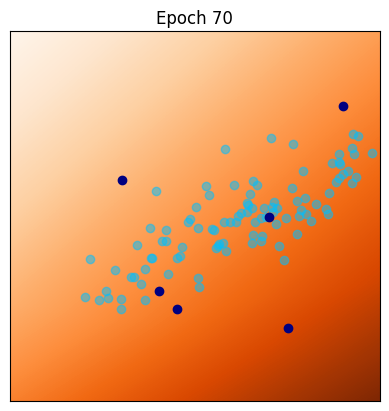

[71/100] 	Loss_D: 6.6238	Loss_G: -0.1619	Lip(D)=0.1881
[72/100] 	Loss_D: 6.5891	Loss_G: -0.1657	Lip(D)=0.1963
[73/100] 	Loss_D: 6.4597	Loss_G: -0.1625	Lip(D)=0.1922
[74/100] 	Loss_D: 6.5236	Loss_G: -0.1670	Lip(D)=0.2004
[75/100] 	Loss_D: 6.4901	Loss_G: -0.1681	Lip(D)=0.1963


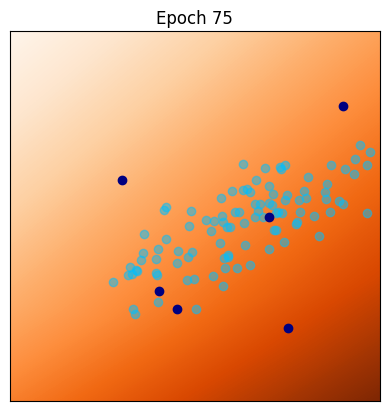

[76/100] 	Loss_D: 6.4598	Loss_G: -0.1695	Lip(D)=0.1984
[77/100] 	Loss_D: 6.4262	Loss_G: -0.1730	Lip(D)=0.2005
[78/100] 	Loss_D: 6.2934	Loss_G: -0.1731	Lip(D)=0.2026
[79/100] 	Loss_D: 6.3588	Loss_G: -0.1775	Lip(D)=0.2047
[80/100] 	Loss_D: 6.2331	Loss_G: -0.1761	Lip(D)=0.2068


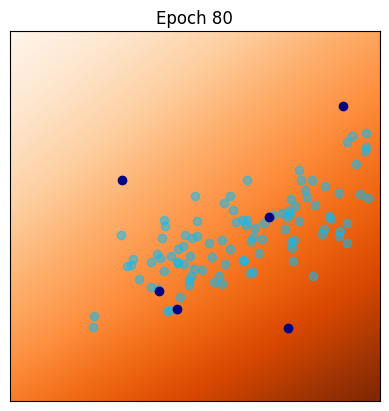

[81/100] 	Loss_D: 6.2005	Loss_G: -0.1789	Lip(D)=0.2210
[82/100] 	Loss_D: 6.1716	Loss_G: -0.1810	Lip(D)=0.2171
[83/100] 	Loss_D: 6.0432	Loss_G: -0.1837	Lip(D)=0.2192
[84/100] 	Loss_D: 6.1957	Loss_G: -0.1860	Lip(D)=0.2153
[85/100] 	Loss_D: 6.1640	Loss_G: -0.1879	Lip(D)=0.2175


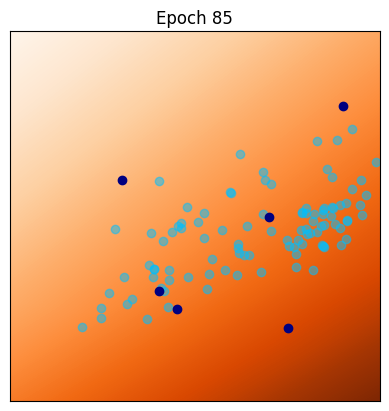

[86/100] 	Loss_D: 6.0390	Loss_G: -0.1890	Lip(D)=0.2196
[87/100] 	Loss_D: 6.0017	Loss_G: -0.1940	Lip(D)=0.2278
[88/100] 	Loss_D: 6.0599	Loss_G: -0.1902	Lip(D)=0.2299
[89/100] 	Loss_D: 6.0277	Loss_G: -0.1977	Lip(D)=0.2321
[90/100] 	Loss_D: 5.9068	Loss_G: -0.1985	Lip(D)=0.2402


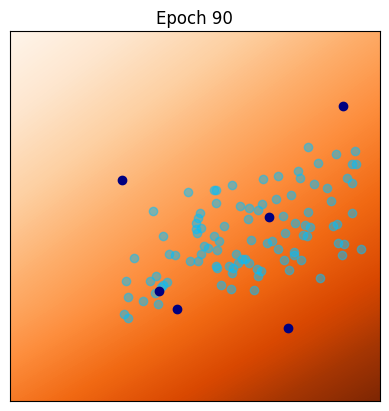

[91/100] 	Loss_D: 5.8717	Loss_G: -0.1996	Lip(D)=0.2365
[92/100] 	Loss_D: 5.7772	Loss_G: -0.2011	Lip(D)=0.2387
[93/100] 	Loss_D: 5.8982	Loss_G: -0.2031	Lip(D)=0.2409
[94/100] 	Loss_D: 5.7708	Loss_G: -0.2098	Lip(D)=0.2431
[95/100] 	Loss_D: 5.7444	Loss_G: -0.2100	Lip(D)=0.2453


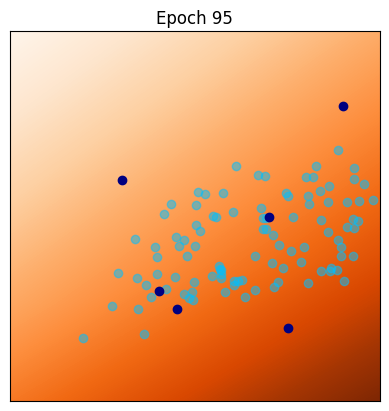

[96/100] 	Loss_D: 5.6293	Loss_G: -0.2047	Lip(D)=0.2648
[97/100] 	Loss_D: 5.5089	Loss_G: -0.2106	Lip(D)=0.2612
[98/100] 	Loss_D: 5.5564	Loss_G: -0.2202	Lip(D)=0.2576
[99/100] 	Loss_D: 5.5266	Loss_G: -0.2203	Lip(D)=0.2655


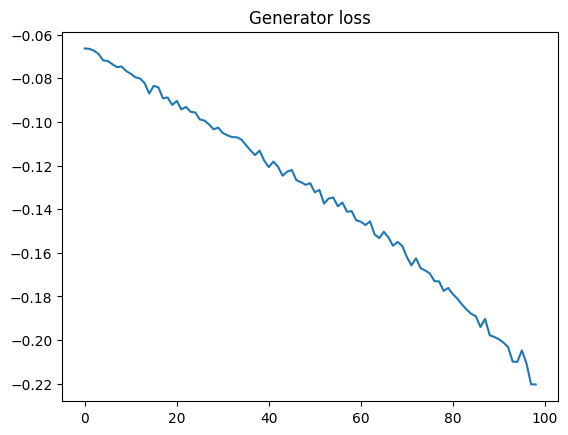

In [ ]:
def train_wgan(num_epochs, lr_g, lr_d, niterD, niterG, gpw, log_every=5, x=x, y=y):
    torch.manual_seed(1)  # initialize random seed for reproducibility

    # Initialize generator and discriminator
    G = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
    D = Discriminator(n_in=d, n_hid=10).to(device)

    optimG = optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    optimD = optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))

    Glosses = []
    Dlosses = []

    for epoch in range(1, num_epochs):
        ############################
        ### Train discriminator (niterD iterations)
        ############################
        for _ in range(niterD):
            optimD.zero_grad()

            # Generate fake data
            z = torch.randn(b, n_in, device=device)
            x_fake = G(z)

            # Calculate WGAN loss
            D_real = D(y)
            D_fake = D(x_fake)
            Dloss = -(torch.mean(D_real) - torch.mean(D_fake))

            # Gradient Penalty
            gp = gradient_penalty(D, x_fake, y)
            Dloss += gp * gpw

            # Backpropagation and optimization
            Dloss.backward()
            optimD.step()

        ############################
        ### Train generator (niterG iterations)
        ############################
        for _ in range(niterG):
            optimG.zero_grad()

            # Generate fake data
            z = torch.randn(b, n_in, device=device)
            x_fake = G(z)

            # Calculate WGAN loss for generator
            D_fake = D(x_fake)
            Gloss = -torch.mean(D_fake)

            # Backpropagation and optimization
            Gloss.backward()
            optimG.step()

        # Output training stats
        print('[%d/%d] \tLoss_D: %.4f\tLoss_G: %.4f\tLip(D)=%.4f'
              % (epoch, num_epochs, Dloss.item(), Gloss.item(), lipconstant(D, x, y).item()))
        Glosses.append(Gloss.item())
        Dlosses.append(Dloss.item())

        if epoch % log_every == 0:
            Dxgrid = D(xgrid).detach().cpu().numpy().reshape(nr, nc)
            z = torch.randn(b, n_in, device=device)
            x = G(z)
            xd = x.detach().squeeze(1)
            strtitle = 'Epoch ' + str(epoch)
            fig = plt.figure(dpi=100)
            plt.xticks([])
            plt.yticks([])
            plt.imshow(Dxgrid, cmap='Oranges', extent=extent)
            plt.scatter(xd[:, 0].cpu(), xd[:, 1].cpu(), c='deepskyblue', alpha=.5)
            plt.scatter(y[:, 0].cpu(), y[:, 1].cpu(), c='navy')
            plt.title(strtitle)
            plt.show()

    plt.figure(dpi=100)
    plt.plot(Glosses)
    plt.title('Generator loss')
    plt.show()

    return G, D

configs = [
    {'lr_g': 0.0001, 'lr_d': 0.0004, 'niterD': 5, 'niterG': 1, 'gpw': 10, 'x':x, 'y':y},
    {'lr_g': 0.0002, 'lr_d': 0.0002, 'niterD': 1, 'niterG': 1, 'gpw': 10, 'x':x, 'y':y},
    {'lr_g': 0.0001, 'lr_d': 0.0001, 'niterD': 5, 'niterG': 1, 'gpw': 1, 'x':x, 'y':y},
    {'lr_g': 0.0004, 'lr_d': 0.0004, 'niterD': 1, 'niterG': 1, 'gpw': 10, 'x':x, 'y':y}
]

for idx, config in enumerate(configs):
    print(f"Experiment {idx + 1}: {config}")
    G, D = train_wgan(num_epochs=100, **config)
    torch.save(G.state_dict(), f'G_experiment_{idx + 1}.pth')
    torch.save(D.state_dict(), f'D_experiment_{idx + 1}.pth')

## Train the generator only

QUESTION: For a fixed discriminator, optimize only the generator only. Can you explain what is happening then?

We can see that our program converges, but it does not function correctly. The points converge to the bottom right corner because the discriminator the discriminator is not updated, thus the generator starts to overfit to the discriminator's fixed responses rather than learning to produce correct data.

[1/100] 	Loss_D: -0.0770	Loss_G: -0.0696	Lip(D)=0.0753
[2/100] 	Loss_D: -0.0770	Loss_G: -0.0756	Lip(D)=0.0753
[3/100] 	Loss_D: -0.0770	Loss_G: -0.0800	Lip(D)=0.0753
[4/100] 	Loss_D: -0.0770	Loss_G: -0.0886	Lip(D)=0.0753
[5/100] 	Loss_D: -0.0770	Loss_G: -0.0976	Lip(D)=0.0753


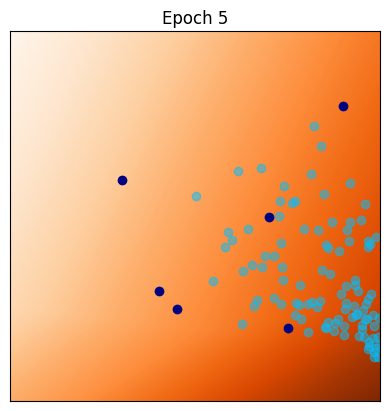

[6/100] 	Loss_D: -0.0770	Loss_G: -0.1047	Lip(D)=0.0898
[7/100] 	Loss_D: -0.0770	Loss_G: -0.1140	Lip(D)=0.0825
[8/100] 	Loss_D: -0.0770	Loss_G: -0.1193	Lip(D)=0.0898
[9/100] 	Loss_D: -0.0770	Loss_G: -0.1256	Lip(D)=0.0898
[10/100] 	Loss_D: -0.0770	Loss_G: -0.1284	Lip(D)=0.0825


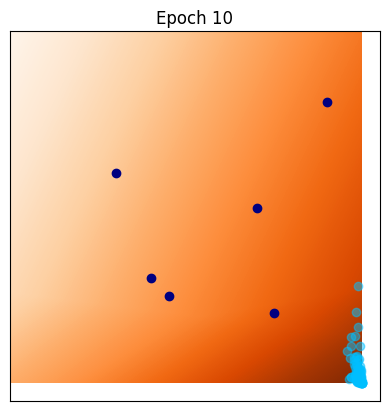

[11/100] 	Loss_D: -0.0770	Loss_G: -0.1303	Lip(D)=0.0935
[12/100] 	Loss_D: -0.0770	Loss_G: -0.1311	Lip(D)=0.1165
[13/100] 	Loss_D: -0.0770	Loss_G: -0.1315	Lip(D)=0.0935
[14/100] 	Loss_D: -0.0770	Loss_G: -0.1316	Lip(D)=0.1057
[15/100] 	Loss_D: -0.0770	Loss_G: -0.1320	Lip(D)=0.0862


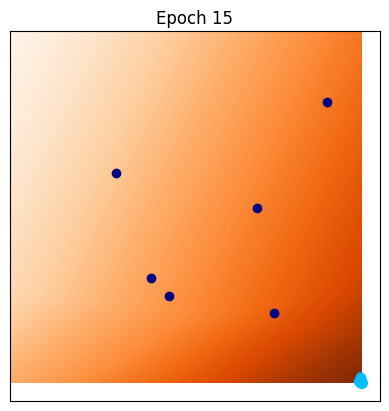

[16/100] 	Loss_D: -0.0770	Loss_G: -0.1322	Lip(D)=0.1154
[17/100] 	Loss_D: -0.0770	Loss_G: -0.1322	Lip(D)=0.1118
[18/100] 	Loss_D: -0.0770	Loss_G: -0.1323	Lip(D)=0.1045
[19/100] 	Loss_D: -0.0770	Loss_G: -0.1324	Lip(D)=0.1202
[20/100] 	Loss_D: -0.0770	Loss_G: -0.1324	Lip(D)=0.1251


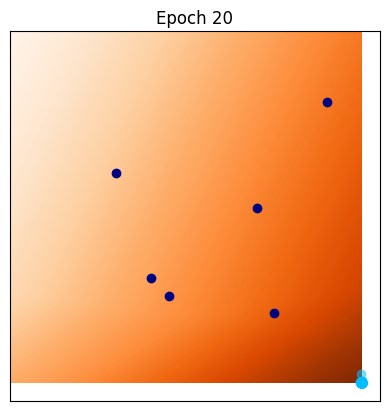

[21/100] 	Loss_D: -0.0770	Loss_G: -0.1325	Lip(D)=0.1118
[22/100] 	Loss_D: -0.0770	Loss_G: -0.1324	Lip(D)=0.0948
[23/100] 	Loss_D: -0.0770	Loss_G: -0.1325	Lip(D)=0.0923
[24/100] 	Loss_D: -0.0770	Loss_G: -0.1325	Lip(D)=0.1032
[25/100] 	Loss_D: -0.0770	Loss_G: -0.1325	Lip(D)=0.0923


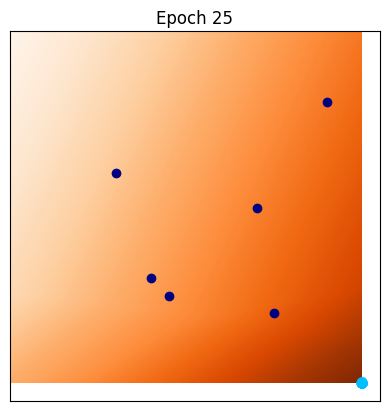

[26/100] 	Loss_D: -0.0770	Loss_G: -0.1325	Lip(D)=0.1142
[27/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1178
[28/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1020
[29/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1166
[30/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1142


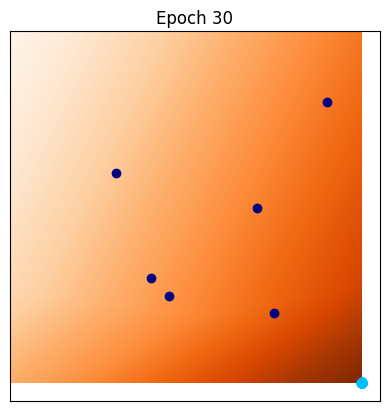

[31/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1057
[32/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.0948
[33/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1118
[34/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1045
[35/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1154


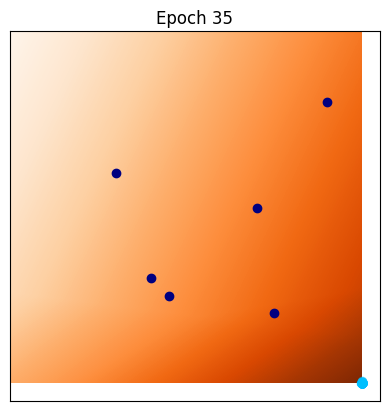

[36/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1057
[37/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.0948
[38/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.0948
[39/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.0995
[40/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1264


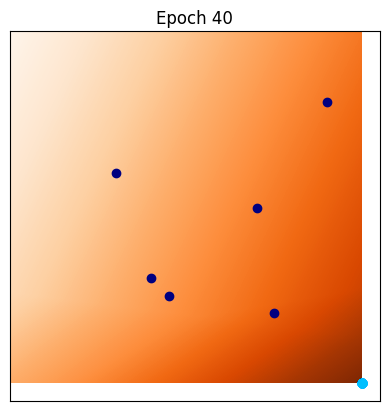

[41/100] 	Loss_D: -0.0770	Loss_G: -0.1326	Lip(D)=0.1045
[42/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1142
[43/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1105
[44/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1202
[45/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1045


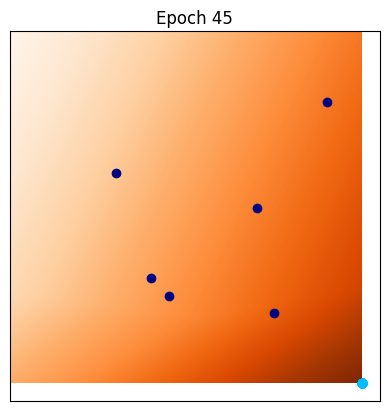

[46/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1215
[47/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1057
[48/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1227
[49/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.0995
[50/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1215


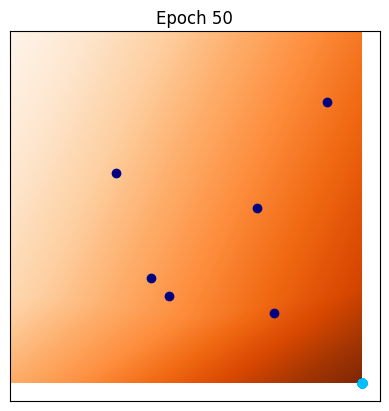

[51/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1215
[52/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1093
[53/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1057
[54/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1045
[55/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1142


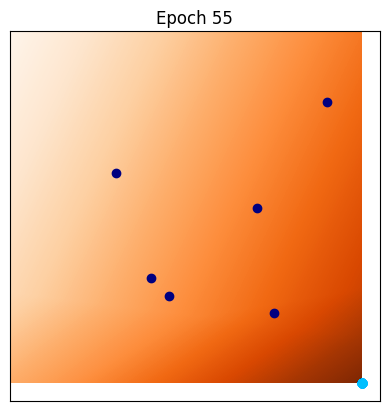

[56/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1093
[57/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1020
[58/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1178
[59/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1154
[60/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1142


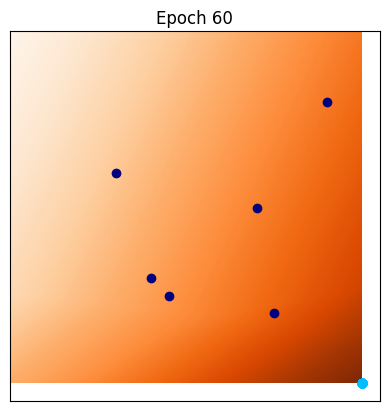

[61/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1045
[62/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1057
[63/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1130
[64/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1045
[65/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1032


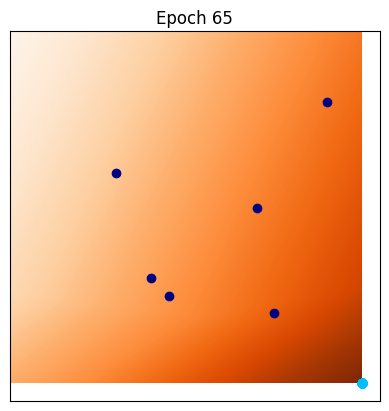

[66/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1190
[67/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.0923
[68/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1118
[69/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1142
[70/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1093


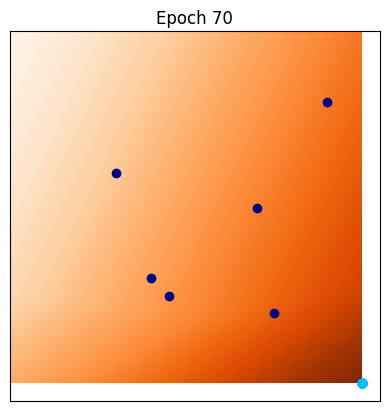

[71/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1118
[72/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1215
[73/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1130
[74/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1142
[75/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1190


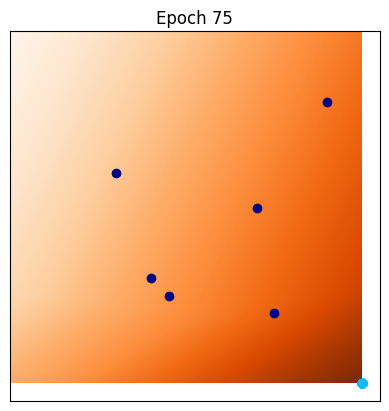

[76/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1190
[77/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1264
[78/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1227
[79/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1202
[80/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1154


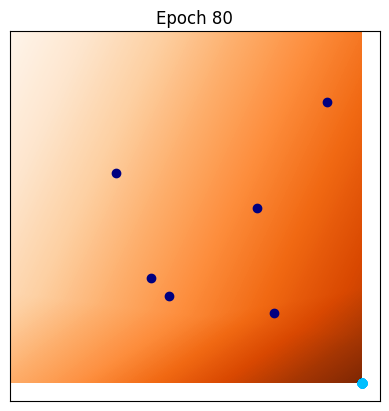

[81/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1165
[82/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1154
[83/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1165
[84/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1057
[85/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1045


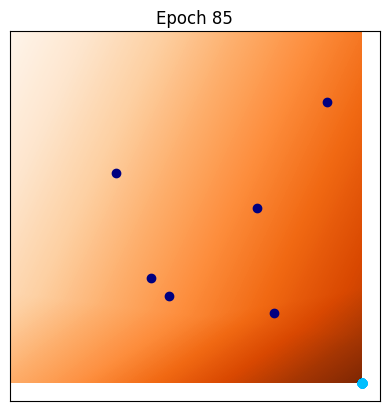

[86/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1118
[87/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1240
[88/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1105
[89/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.0960
[90/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1130


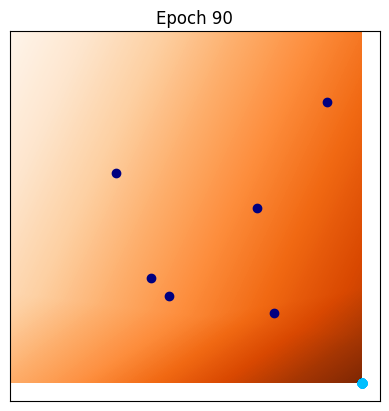

[91/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1227
[92/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1215
[93/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1020
[94/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1190
[95/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1239


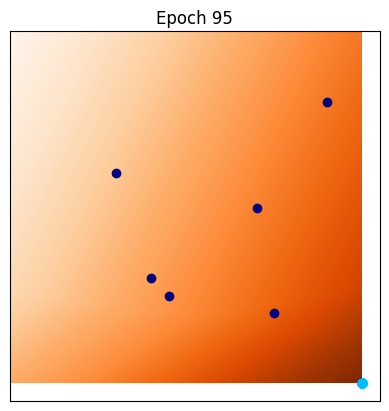

[96/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1032
[97/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1045
[98/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1240
[99/100] 	Loss_D: -0.0770	Loss_G: -0.1327	Lip(D)=0.1057


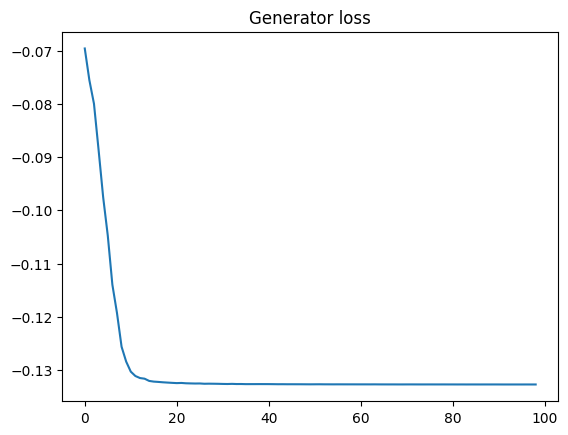

<All keys matched successfully>

In [ ]:
## parameters for training
n_epochs = 100
niterD=1000
niterG=10
gpw = .1

lr = 0.002      # learning rate for generator
lrdisc = 0.002  # learning rate for discriminator
beta_1 = 0.5
beta_2 = 0.999

torch.manual_seed(1)  # initialize random seed for reproducibility

# Initialize generators and discriminators
G = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
optimG = optim.Adam(G.parameters(), lr=lr)

D = Discriminator(n_in=d, n_hid=10).to(device)
D.eval()


Glosses = []
Dlosses = []

iter_display = 5

# Main loop
for epoch in range(1,n_epochs):


    ############################
    ### Train generator (niterG iterations)
    ############################
    for iter in range(0,niterG):
        optimG.zero_grad()

        # Generate fake data
        z = torch.randn(b, n_in, device=device)
        x_fake = G(z)

        # Calculate WGAN loss for generator
        D_fake = D(x_fake)
        Gloss = -torch.mean(D_fake)

        # Backpropagation and optimization
        Gloss.backward()
        optimG.step()

    # Output training stats
    print('[%d/%d] \tLoss_D: %.4f\tLoss_G: %.4f\tLip(D)=%.4f'
      % (epoch, n_epochs, Dloss.item(), Gloss.item(),lipconstant(D,x,y).item()))
    Glosses.append(Gloss.item())
    Dlosses.append(Dloss.item())

    if(epoch % iter_display == 0):
        Dxgrid = D(xgrid).detach().cpu().numpy().reshape(nr,nc)
        z = torch.randn(b, n_in, device=device)
        x = G(z)
        xd = x.detach().squeeze(1)
        strtitle = 'Epoch '+str(epoch)
        fig = plt.figure(dpi=100)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(Dxgrid,cmap = 'Oranges', extent=extent)
        plt.scatter(xd[:, 0].cpu(), xd[:,1].cpu(),c='deepskyblue',alpha=.5)
        plt.scatter(y[:, 0].cpu(), y[:,1].cpu(),c='navy')
        plt.title(strtitle)
        plt.show()


plt.figure(dpi=100)
plt.plot(Glosses)
plt.title('Generator loss')
plt.show()

# Save final generator for later use
wgan = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
wgan.load_state_dict(G.state_dict())

<br/><br/><br/><br/>

# BONUS Exercise (to do at home) : Learn a standard GAN

## Define Loss for GAN training

For stable GAN training uses the Binary cross-entropy loss which takes labeled data as input.

The data points $y$ should correspond to values $\approx 1$, whereas fake points $x$ should get values $\approx 0$.

We also introduce the sigmoid function. for displaying purpose: for GAN training, the discriminator values in $[0,1]$ will be obtained by applying after $D$.

In [ ]:
criterion = nn.BCEWithLogitsLoss()
V1 = torch.full((n,1), 1. , dtype=torch.float, device=device)
V0 = torch.full((b,1), 0. , dtype=torch.float, device=device)

sig = nn.Sigmoid()

## Train the discriminator for a fixed generator

QUESTION: Complete the following code at the blocks ###...###

In [ ]:
torch.manual_seed(1)  # initialize random seed for reproducibility

# parameters for discriminator optimization
lrdisc = 0.002
beta_1 = 0.5
beta_2 = 0.999
niterD=1000

# Initialize generators and discriminators
G = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
optimG = optim.Adam(G.parameters(), lr=lr)

D = Discriminator(n_in=d, n_hid=10).to(device)
optimD = optim.Adam(D.parameters(), lr=lrdisc, betas=(beta_1, 0.999))

iter_display = 100  # display current configuration each iter_display iteration

Dlosses = []

for iter in range(0,niterD):

    ### UPDATE OF D ###
    ### ... ###


    ### SAVE LOSS ###
    Dlosst = Dloss.item()
    Dlosses.append(-Dlosst)

    if(iter%iter_display == 0):
        print('[%d/%d], %f' % (iter, niterD, Dlosst))
        Dxgrid = sig(D(xgrid)).detach().cpu().numpy().reshape(nr,nc)
        x = G(z)
        xd = x.detach().squeeze(1)
        strtitle = 'Iter '+str(iter)
        fig = plt.figure(dpi=100)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(Dxgrid,cmap = 'Oranges', extent=extent)  # discriminator
        plt.scatter(xd[:, 0].cpu(), xd[:,1].cpu(),c='deepskyblue',alpha=.5)
        plt.scatter(y[:, 0].cpu(), y[:,1].cpu(),c='navy')
        plt.title(strtitle)
        plt.show()


### Plot the evolution of the discriminator loss ###
plt.figure(dpi=100)
plt.plot(Dlosses)
plt.title('Discriminator loss')
plt.show()

## Train both the Generator and Discriminator

In [ ]:
lr = 0.002   # learning rate for generator
lrdisc = 0.002   # learning rate for generator

## parameters for training
n_epochs = 100
niterD=100
niterG=1

torch.manual_seed(1)  # initialize random seed for reproducibility

# Initialize generators and discriminators
G = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
optimG = optim.Adam(G.parameters(), lr=lr)

D = Discriminator(n_in=d, n_hid=10).to(device)
optimD = optim.Adam(D.parameters(), lr=lrdisc, betas=(beta_1, beta_2))

Glosses = []
Dlosses = []

iter_display = 10

# Main loop
for epoch in range(n_epochs):

    ############################
    ### Train discriminator (niterD iterations)
    ############################
    for iter in range(0,niterD):
        ### ... ###

    ############################
    ### Train generator (niterG iterations)
    ############################
    for iter in range(0,niterG):
        ### ... ###


    # Output training stats
    print('[%d/%d] \tLoss_D: %.4f\tLoss_G: %.4f'
      % (epoch, n_epochs, Dloss.item(), Gloss.item()))
    Glosses.append(Gloss.item())
    Dlosses.append(-Dloss.item())


    if(epoch % iter_display == 0):
        Dxgrid = sig(D(xgrid)).detach().cpu().numpy().reshape(nr,nc)
        z = torch.randn(b, 1, n_in, device=device)
        x = G(z)
        xd = x.detach().squeeze(1)
        strtitle = 'Epoch '+str(epoch)
        fig = plt.figure(dpi=100)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(Dxgrid,cmap = 'Oranges', extent=extent)  # discriminator
        plt.scatter(xd[:, 0].cpu(), xd[:,1].cpu(),c='deepskyblue',alpha=.5)
        plt.scatter(y[:, 0].cpu(), y[:,1].cpu(),c='navy')
        plt.title(strtitle)
        plt.show()

# Save final generator for later use
gan = Generator(n_in=n_in, n_out=d, n_hid=10, nlayers=3, device=device)
gan.load_state_dict(G.state_dict())

### Plot the evolution of the discriminator loss ###
plt.figure(dpi=100)
plt.plot(Glosses)
plt.title('Generator loss')
plt.show()